# **🏗️ Complete Project Flow**

1. Project Setup
       ↓
2. Kaggle API Authentication
       ↓
3. Download Dataset to Colab Runtime
       ↓
4. Understand Dataset Structure
       ↓
5. Dataset Statistics
       ↓
6. Check Class Distribution
       ↓
7. Visualize Sample X-rays
       ↓
8. Check Image Quality / Corrupt Images
       ↓
9. Data Preprocessing
       ↓
10. Train / Validation / Test Split
       ↓
11. Data Augmentation
       ↓
12. Build DenseNet121
       ↓
13. Transfer Learning
       ↓
14. Initial Training
       ↓
15. Evaluate Model
       ↓
16. Confusion Matrix
       ↓
17. Precision / Recall / F1
       ↓
18. ROC-AUC
       ↓
19. Training Curves
       ↓
20. Detect Overfitting
       ↓
21. Fine-Tuning
       ↓
22. Re-training
       ↓
23. Compare Results
       ↓
24. Select Best Model
       ↓
25. Save Model
       ↓
26. Test on New X-ray
       ↓
27. Final Prediction
       ↓
28. Project Documentation

# **Important Rule About the Dataset**

Kaggle
   ↓
Kaggle API
   ↓
Colab Runtime
   ↓
Dataset analysis
   ↓
Training
   ↓
Evaluation
   ↓
Experimentation
   ↓
Best result
   ↓
THEN save important files/model to Drive

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


CPU
↓
Slower deep-learning training

GPU
↓
Parallel computation
↓
Faster training

In [ ]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torchvision

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Libraries imported successfully")

Libraries imported successfully


**nstall/Check Required Libraries**

| Library      | Purpose                         |
| ------------ | ------------------------------- |
| PyTorch      | Deep learning                   |
| Torchvision  | CNN models and image processing |
| NumPy        | Numerical operations            |
| Pandas       | Dataset/data analysis           |
| Matplotlib   | Visualization                   |
| Seaborn      | Statistical plots               |
| PIL          | Image processing                |
| Scikit-learn | Evaluation metrics              |


**Inspect a dataset WITHOUT downloading it**

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [ ]:
!pip -q install kaggle

In [ ]:
import os
import getpass

kaggle_token = getpass.getpass("Enter your Kaggle API token: ")

os.environ["KAGGLE_API_TOKEN"] = kaggle_token

print("Kaggle API token has been set.")

Enter your Kaggle API token: ··········
Kaggle API token has been set.


In [ ]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 16.4 MB/s eta 0:00:00


In [ ]:
import kaggle

print("Kaggle version:", kaggle.__version__)

Kaggle version: 2.2.4


In [ ]:
!kaggle datasets download -d reflex7/cxr-data-set -p /content/cxr_dataset

Dataset URL: https://www.kaggle.com/datasets/reflex7/cxr-data-set
License(s): MIT
100% 16.9G/16.9G [04:02<00:00, 74.9MB/s]



In [ ]:
from pathlib import Path

download_dir = Path("/content/cxr_dataset")

for file in download_dir.iterdir():
    print(file.name, "→", file.stat().st_size / (1024**3), "GB")

cxr-data-set.zip → 16.876295989379287 GB


In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   65G   49G  57% /


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/cxr_dataset/cxr-data-set.zip")
extract_path = Path("/content/cxr_data")

extract_path.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extraction completed.")

Dataset extraction completed.


Extract dataset

In [ ]:
from pathlib import Path

for item in Path("/content/cxr_data").iterdir():
    print(item)

/content/cxr_data/Normal
/content/cxr_data/Tuberculosis
/content/cxr_data/Pneumonia
/content/cxr_data/Covid


In [ ]:
from pathlib import Path
from collections import Counter

data_dir = Path("/content/cxr_data")

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

class_counts = {}

for class_dir in data_dir.iterdir():
    if class_dir.is_dir():
        count = sum(
            1 for file in class_dir.rglob("*")
            if file.is_file() and file.suffix.lower() in valid_extensions
        )
        class_counts[class_dir.name] = count

print("Image count by class:\n")

for class_name, count in class_counts.items():
    print(f"{class_name:15s}: {count:,}")

normal_count = class_counts.get("Normal", 0)
pneumonia_count = class_counts.get("Pneumonia", 0)

print("\n--------------------------------")
print(f"Normal + Pneumonia: {normal_count + pneumonia_count:,}")

Image count by class:

Normal         : 18,097
Tuberculosis   : 18,002
Pneumonia      : 18,187
Covid          : 18,011

--------------------------------
Normal + Pneumonia: 36,284


36,284 images
      ↓

1. File types
      ↓

2. Corrupted images
      ↓

3. Image dimensions
      ↓

4. Duplicate images
      ↓

5. Random visual inspection
      ↓
      
Clean dataset

In [ ]:
from collections import Counter
from pathlib import Path

target_classes = ["Normal", "Pneumonia"]

extension_counts = Counter()

for class_name in target_classes:
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file():
            extension_counts[file.suffix.lower()] += 1

print("Image file types:\n")

for extension, count in extension_counts.items():
    print(f"{extension:8s}: {count:,}")

Image file types:

.jpg    : 5,980
.jpeg   : 12,475
.png    : 17,829


**Check file extensions**


What does this do?

It tells us what types of image files are actually inside Normal and Pneumonia.

In [ ]:
from PIL import Image

corrupt_images = []

for class_name in target_classes:
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in valid_extensions:
            try:
                with Image.open(file) as img:
                    img.verify()
            except Exception:
                corrupt_images.append(file)

print("Total corrupt/unreadable images:", len(corrupt_images))

if corrupt_images:
    print("\nFirst 10 corrupt files:")
    for file in corrupt_images[:10]:
        print(file)
else:
    print("No corrupt images found.")

Total corrupt/unreadable images: 0
No corrupt images found.


**Find corrupted/unreadable images**


Why?

An image may have a .jpg extension but still be damaged or unreadable.

We don't want the training process to crash halfway through because of one bad image.

In [ ]:
from collections import Counter

image_sizes = Counter()
sample_count = 0

for class_name in target_classes:
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in valid_extensions:
            try:
                with Image.open(file) as img:
                    image_sizes[img.size] += 1
                    sample_count += 1
            except:
                pass

print("Total readable images:", sample_count)
print("\nMost common image dimensions:")

for size, count in image_sizes.most_common(15):
    print(f"{size}: {count:,}")

Total readable images: 36284

Most common image dimensions:
(299, 299): 7,790
(512, 512): 3,500
(232, 232): 2,947
(1024, 1024): 2,494
(256, 256): 655
(400, 300): 529
(4020, 4892): 51
(4892, 4020): 29
(1008, 704): 23
(1072, 648): 20
(992, 608): 19
(992, 592): 18
(1080, 728): 18
(1216, 872): 17
(1136, 680): 16


**Check image dimensions**


Why?

Medical X-rays can have different resolutions.

We want to know the original dimensions before preprocessing everything to 224×224.

In [ ]:
mode_counts = Counter()

for class_name in target_classes:
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in valid_extensions:
            try:
                with Image.open(file) as img:
                    mode_counts[img.mode] += 1
            except:
                pass

print("Image modes:\n")

for mode, count in mode_counts.items():
    print(f"{mode}: {count:,}")

Image modes:

RGB: 14,104
L: 21,803
P: 324
RGBA: 53


**Check image mode**


Why?

We need to know whether the images are:

L       → grayscale
RGB     → 3-channel color
RGBA    → 4-channel

Chest X-rays are normally grayscale, but the dataset may store them in different formats

In [ ]:
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(target_classes):
    class_dir = data_dir / class_name

    files = [
        f for f in class_dir.rglob("*")
        if f.is_file() and f.suffix.lower() in valid_extensions
    ]

    selected = random.sample(files, 4)

    for col, file in enumerate(selected):
        with Image.open(file) as img:
            axes[row, col].imshow(img, cmap="gray")

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

<Figure size 1400x700 with 8 Axes>

**Display random Normal and Pneumonia images**

This is very important.

Numbers alone aren't enough. We need to visually inspect whether the images actually look like chest X-rays.

In [ ]:
import hashlib
from collections import defaultdict

hash_to_files = defaultdict(list)

for class_name in target_classes:
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in valid_extensions:
            try:
                with open(file, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                hash_to_files[file_hash].append(file)

            except Exception:
                pass

duplicate_groups = {
    h: files
    for h, files in hash_to_files.items()
    if len(files) > 1
}

duplicate_file_count = sum(len(files) - 1 for files in duplicate_groups.values())

print("Unique image hashes:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))
print("Duplicate files beyond first copy:", duplicate_file_count)

Unique image hashes: 30283
Duplicate groups: 5912
Duplicate files beyond first copy: 6001


# **PHASE 1C — Duplicate & Class Analysis**

**Check exact duplicate images**

Why?

A large dataset can contain the same image more than once. If the same image appears in both training and validation/test sets, it causes data leakage and can make the model's performance look artificially high.

We'll first look for exact duplicates using an MD5 hash.

In [ ]:
cross_class_duplicates = []

for file_hash, files in hash_to_files.items():
    classes_found = {file.parent.name for file in files}

    if len(classes_found) > 1:
        cross_class_duplicates.append((file_hash, files))

print("Cross-class duplicate groups:", len(cross_class_duplicates))

if cross_class_duplicates:
    print("\nExamples:")

    for file_hash, files in cross_class_duplicates[:10]:
        print("\nHash:", file_hash)
        for file in files:
            print(" ", file)

Cross-class duplicate groups: 0


**Check duplicates across classes**

This is especially important.

Suppose the exact same X-ray occurs as:

Normal/image123.jpg

and:

Pneumonia/image456.jpg

That's a serious label conflict.

In [ ]:
normal_count = class_counts["Normal"]
pneumonia_count = class_counts["Pneumonia"]

total = normal_count + pneumonia_count

normal_percentage = (normal_count / total) * 100
pneumonia_percentage = (pneumonia_count / total) * 100

print(f"Total images       : {total:,}")
print(f"Normal             : {normal_count:,} ({normal_percentage:.2f}%)")
print(f"Pneumonia          : {pneumonia_count:,} ({pneumonia_percentage:.2f}%)")

Total images       : 36,284
Normal             : 18,097 (49.88%)
Pneumonia          : 18,187 (50.12%)


**Calculate class balance**

We already know the counts, but let's calculate the percentages.
Approximately:

Normal      ≈ 49.88%
Pneumonia   ≈ 50.12%

That's excellent balance.

This means we probably won't need aggressive class weighting just to compensate for class imbalance.

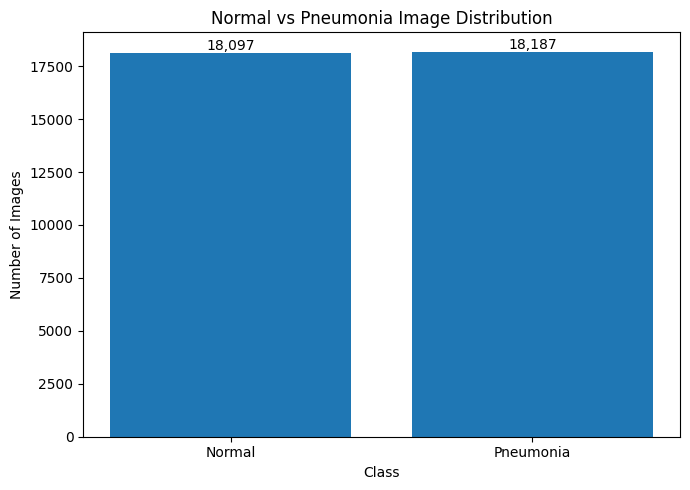

In [ ]:
classes = ["Normal", "Pneumonia"]
counts = [normal_count, pneumonia_count]

plt.figure(figsize=(7, 5))

bars = plt.bar(classes, counts)

plt.title("Normal vs Pneumonia Image Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Plot class distribution**

A graph will be useful for your project report.

**Why do we need this?**

This will become part of your EDA section.

You can later show your guide:

"The selected dataset contains approximately equal numbers of Normal and Pneumonia images, reducing the risk of severe class imbalance."

In [ ]:
records = []

label_map = {
    "Normal": 0,
    "Pneumonia": 1
}

for class_name, label in label_map.items():
    class_dir = data_dir / class_name

    for file in class_dir.rglob("*"):
        if file.is_file() and file.suffix.lower() in valid_extensions:
            records.append({
                "image_path": str(file),
                "label": label,
                "class_name": class_name
            })

df = pd.DataFrame(records)

print("Dataset DataFrame created.")
print("Shape:", df.shape)

display(df.head())

Dataset DataFrame created.
Shape: (36284, 3)


,image_path,label,class_name
0,/content/cxr_data/Normal/NORMAL(845).jpg,0,Normal
1,/content/cxr_data/Normal/NORMAL2-IM-1269-0001-...,0,Normal
2,/content/cxr_data/Normal/3a5b4890-bfe1-4953-ad...,0,Normal
3,/content/cxr_data/Normal/NORMAL(675).jpg,0,Normal
4,/content/cxr_data/Normal/NORMAL2-IM-0816-0001....,0,Normal


**create a DataFrame containing image paths and labels**

This will make the rest of our pipeline much easier.

Instead of repeatedly scanning folders, we'll create a table:

In [ ]:
print("Label counts:")
print(df["label"].value_counts().sort_index())

print("\nClass counts:")
print(df["class_name"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Label counts:
label
0    18097
1    18187
Name: count, dtype: int64

Class counts:
class_name
Pneumonia    18187
Normal       18097
Name: count, dtype: int64

Missing values:
image_path    0
label         0
class_name    0
dtype: int64


**Verify labels**

Before proceeding, let's make absolutely sure the DataFrame has no unexpected labels.

# **Important finding: duplicates**

We have:

36,284 total images
30,283 unique image hashes
5,912 duplicate groups
6,001 duplicate copies
0 cross-class duplicates ✅

So we should NOT randomly split the 36,284 images yet. If duplicate copies go into both training and validation/test, we could get data leakage and an artificially high accuracy.

**instead, we'll first create a deduplicated dataset of 30,283 unique images.**

The class balance is still excellent, and there are no missing labels.

36,284 raw images

       ↓

Exact duplicate detection

       ↓

30,283 unique images

       ↓

Stratified split

       ↓

70% Training

15% Validation

15% Test

       ↓

DenseNet121

In [ ]:
# Add the image hash to our dataframe

image_hashes = []

for file_path in df["image_path"]:
    try:
        with open(file_path, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        image_hashes.append(file_hash)
    except Exception:
        image_hashes.append(None)

df["image_hash"] = image_hashes

print("Total rows:", len(df))
print("Unique hashes:", df["image_hash"].nunique())

Total rows: 36284
Unique hashes: 30283


**Create deduplicated DataFrame**

We already calculated the hashes, so we don't need to read the images again.

In [ ]:
df_clean = df.drop_duplicates(
    subset="image_hash",
    keep="first"
).reset_index(drop=True)

print("Original images :", len(df))
print("Clean images    :", len(df_clean))
print("Removed copies  :", len(df) - len(df_clean))

Original images : 36284
Clean images    : 30283
Removed copies  : 6001


**Remove duplicate copies**

What does this do?

For every identical image, we keep only the first occurrence.

We're not deleting files from your dataset.

We're simply creating a clean list of images that our model will use.

This is safer and lets us go back to the original dataset if necessary.

In [ ]:
clean_class_counts = df_clean["class_name"].value_counts()

print("Clean dataset class distribution:\n")

for class_name, count in clean_class_counts.items():
    percentage = (count / len(df_clean)) * 100
    print(f"{class_name:12s}: {count:,} ({percentage:.2f}%)")

Clean dataset class distribution:

Normal      : 16,441 (54.29%)
Pneumonia   : 13,842 (45.71%)


**Verify class balance after deduplication**

This is very important because duplicate removal could potentially affect the balance.

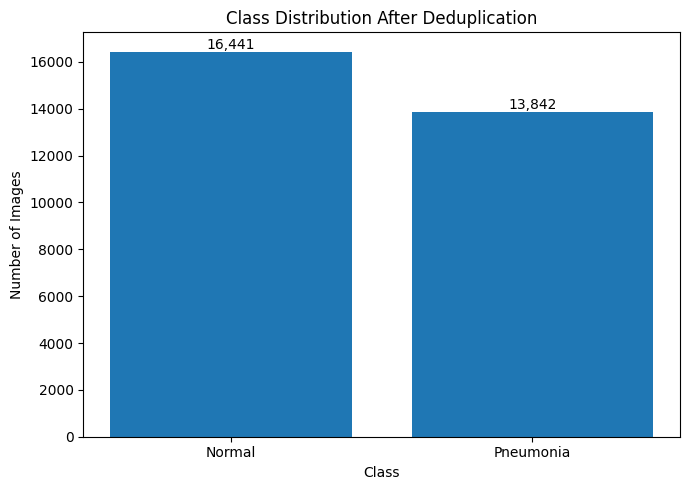

In [ ]:
clean_counts = df_clean["class_name"].value_counts()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    clean_counts.index,
    clean_counts.values
)

plt.title("Class Distribution After Deduplication")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar, count in zip(bars, clean_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Plot clean class distribution**

Now we'll visualize the actual dataset that will be used for training.

Why?

This graph is useful for your project documentation.

You can explain:

"Before splitting the data, exact duplicate images were removed to prevent data leakage. The resulting dataset was checked for class balance."

In [ ]:
duplicate_hashes_after = (
    df_clean["image_hash"]
    .duplicated()
    .sum()
)

print("Duplicate hashes after cleaning:", duplicate_hashes_after)

Duplicate hashes after cleaning: 0


**Check for duplicate hashes again**

We should verify that our clean dataset contains no duplicate hashe

In [ ]:
clean_csv_path = "/content/clean_cxr_dataset.csv"

df_clean.to_csv(
    clean_csv_path,
    index=False
)

print("Clean dataset CSV saved to:")
print(clean_csv_path)

print("\nCSV shape:", df_clean.shape)

Clean dataset CSV saved to:
/content/clean_cxr_dataset.csv

CSV shape: (30283, 4)


**Save the clean dataset CSV**

We should save our clean dataset information.

**why save this?**

The CSV contains:

image_path
label
class_name
image_hash

We can reuse it without scanning the 30k images again.

In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    stratify=df_clean["label"],
    random_state=SEED
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))
print("Total      :", len(train_df) + len(val_df) + len(test_df))

Training   : 21198
Validation : 4542
Test       : 4543
Total      : 30283


**Create Train / Validation / Test split**

Now we finally split the dataset.

**Our strategy**

We'll use:

70% → Training
15% → Validation
15% → Test

And importantly, we'll use stratification.

That means both classes remain approximately equally represented in each split.

In [ ]:
def show_split_distribution(name, split_df):
    counts = split_df["class_name"].value_counts()
    percentages = split_df["class_name"].value_counts(normalize=True) * 100

    print(f"\n{name}")
    print("-" * 35)

    for class_name in ["Normal", "Pneumonia"]:
        print(
            f"{class_name:12s}: "
            f"{counts.get(class_name, 0):,} "
            f"({percentages.get(class_name, 0):.2f}%)"
        )

show_split_distribution("TRAINING SET", train_df)
show_split_distribution("VALIDATION SET", val_df)
show_split_distribution("TEST SET", test_df)


TRAINING SET
-----------------------------------
Normal      : 11,509 (54.29%)
Pneumonia   : 9,689 (45.71%)

VALIDATION SET
-----------------------------------
Normal      : 2,466 (54.29%)
Pneumonia   : 2,076 (45.71%)

TEST SET
-----------------------------------
Normal      : 2,466 (54.28%)
Pneumonia   : 2,077 (45.72%)


**Verify split class distribution**

This is very important.

We want to verify that stratification worked.

In [ ]:
train_df.to_csv("/content/train.csv", index=False)
val_df.to_csv("/content/validation.csv", index=False)
test_df.to_csv("/content/test.csv", index=False)

print("Saved:")
print("✓ /content/train.csv")
print("✓ /content/validation.csv")
print("✓ /content/test.csv")

Saved:
✓ /content/train.csv
✓ /content/validation.csv
✓ /content/test.csv


**save the three split CSV files**

Let's save them separately.

Clean Dataset

│
├── train.csv

      ↓

│   Training images

│
├── validation.csv

     ↓

│   Validation images

│
└── test.csv

        ↓
    Test images

# PHASE 3 — PyTorch Data Pipeline.

CSV
 ↓

PyTorch Dataset

 ↓
Read X-ray

 ↓
Convert to RGB

 ↓
Resize to 224 × 224

 ↓
Augmentation (training only)

 ↓
ImageNet normalization

 ↓
DataLoader

 ↓
DenseNet121

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from PIL import Image

print("PyTorch:", torch.__version__)
print("Torchvision imported successfully.")

PyTorch: 2.11.0+cu128
Torchvision imported successfully.


**Import PyTorch libraries**


What does this do?

Now we bring in the PyTorch components needed to load and preprocess images.

**Why?**

We'll use:

Dataset → custom X-ray dataset
DataLoader → load images in batches
transforms → resize, augmentation, normalization
nn → DenseNet classifier and loss function

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


**Set device**

What does this do?

It tells PyTorch whether to use the GPU or CPU.

In [ ]:
IMAGE_SIZE = 224

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

print("Image size:", IMAGE_SIZE)
print("ImageNet mean:", IMAGENET_MEAN)
print("ImageNet std:", IMAGENET_STD)

Image size: 224
ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std: [0.229, 0.224, 0.225]


**Define image size and normalization**

DenseNet121 was originally trained on ImageNet images of approximately 224×224 input size.

We'll therefore standardize our X-rays.

**Why ImageNet normalization?**

Our DenseNet121 will use ImageNet pretrained weights.

Therefore, using ImageNet normalization makes the input distribution more compatible with what the pretrained network originally learned from.

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=7
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations created.")

Training transformations created.


**Define training transformations**

This is one of the most important cells.

We don't want the model to simply memorize the training X-rays.

**We'll use moderate augmentation.**

Why these augmentations?
Resize
Original image
      ↓
224 × 224

Because DenseNet121 expects a fixed input size.

**Horizontal flip**

Allows the model to see slightly different orientations.

**Small rotation**

Handles small variations in X-ray positioning.

**Translation/scale**

Makes the model less dependent on the exact positioning of the lungs.

Important

We're deliberately using **moderate augmentation**, not aggressive transformations.

Medical images shouldn't be distorted heavily because we don't want to create unrealistic X-rays.

In [ ]:
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Validation/Test transformations created.")

Validation/Test transformations created.


**Validation/Test transformations**

We must not use random augmentation on validation or test images.

Otherwise the evaluation could change every time we run it.

TRAIN:
Resize
 ↓

Random augmentation
 ↓

Normalize

VALIDATION/TEST:
Resize
 ↓

Normalize

In [ ]:
class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.dataframe.loc[index, "image_path"]
        label = int(self.dataframe.loc[index, "label"])

        try:
            image = Image.open(image_path).convert("RGB")
        except Exception as e:
            raise RuntimeError(
                f"Could not read image: {image_path}"
            ) from e

        if self.transform:
            image = self.transform(image)

        return image, label

print("ChestXrayDataset class created.")

ChestXrayDataset class created.


**Create custom X-ray Dataset**

Now we'll create the PyTorch Dataset.

**What does this do?**

It takes one row from our CSV/DataFrame:

image_path → /content/cxr_data/Normal/Normal-1067.png
label      → 0

and returns:

image tensor
+
label

**Very important line**
***Image.open(image_path).convert("RGB")***

This solves our earlier problem.

Our dataset contained:

RGB
L
P
RGBA

but DenseNet expects 3-channel input.

So everything becomes:

RGB
 ↓
3 channels

In [ ]:
train_dataset = ChestXrayDataset(
    train_df,
    transform=train_transform
)

val_dataset = ChestXrayDataset(
    val_df,
    transform=eval_transform
)

test_dataset = ChestXrayDataset(
    test_df,
    transform=eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 21198
Validation dataset: 4542
Test dataset: 4543


**create Dataset objects**

Now we connect our DataFrames to the PyTorch Dataset.

In [ ]:
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Image data type:", image.dtype)
print("Label:", label)
print("Label name:", "Normal" if label == 0 else "Pneumonia")

Image tensor shape: torch.Size([3, 224, 224])
Image data type: torch.float32
Label: 0
Label name: Normal


**Test one image**

Before creating a DataLoader, let's make sure the Dataset actually works.

X-ray
 ↓

RGB
 ↓

224 × 224
 ↓

Tensor
 ↓

Normalized
 ↓

3 × 224 × 224

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders recreated successfully.")

print("Training batches   :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Testing batches    :", len(test_loader))

DataLoaders recreated successfully.
Training batches   : 663
Validation batches : 142
Testing batches    : 142


**Create DataLoaders**

Now we create batches.

Instead of giving DenseNet one image at a time:

image
image
image
...

we'll give it batches:

Batch

 ├── image 1
 ├── image 2
 ├── image 3
 ├── ...
 └── image 32

 **Why shuffle=True only for training?**

Training should see images in a different order between epochs.

Validation and test don't need shuffling.

# **What about DenseNet121's existing weights?**

We're using:

ImageNet-pretrained DenseNet121.

So instead of:

Random initialization
        ↓

Train from zero

we have:

ImageNet-trained weights
        ↓

DenseNet121
        ↓

Adapt to X-ray problem

This is **transfer learning.**

The pretrained weights contain useful visual features such as:

Early layers
→ edges
→ textures


Deeper layers
→ shapes
→ complex structures
→ higher-level visual features

For our project, we'll fine-tune them for pneumonia detection.

# **3. What about the new classifier?**

DenseNet121 originally has an ImageNet classifier:

1024 features
       ↓
1000 classes

We don't need 1000 classes.

We need:

1024 features
       ↓
2 classes
       ↓
Normal / Pneumonia

Therefore we replace the original classifier.

The new classifier's weights and biases must be initialized.

PyTorch's Linear layer performs this initialization automatically, but because your guide specifically wants you to know it, we'll explicitly initialize it ourselves so we can clearly explain it.

We'll use Kaiming/He initialization for the new linear-layer weights and zero initialization for its bias.

For Kaiming initialization, the basic idea is:

W∼N(0,
n
in
	​

2
	​

)

where n
in
	​

 is the number of input features.

And:

b=0

This gives us a clean, controlled initialization for our newly created classifier.

# **We're also using class weights**

Remember our distribution:

Normal       54.29%
Pneumonia    45.71%

It's only a mild imbalance.

We will not throw away images.

Instead, we'll calculate class weights from the training data and use them in CrossEntropyLoss.

Conceptually:
# wc=N\C*Nc
where:

N = total training samples
C = number of classes
Nc= number of samples in class c

This gives the slightly smaller Pneumonia class a slightly larger weight.

In [ ]:
from torchvision.models import densenet121, DenseNet121_Weights

weights = DenseNet121_Weights.DEFAULT

model = densenet121(weights=weights)

print("DenseNet121 loaded successfully.")
print("ImageNet pretrained weights:", weights)

DenseNet121 loaded successfully.
ImageNet pretrained weights: DenseNet121_Weights.IMAGENET1K_V1


**Load ImageNet-pretrained DenseNet121**
What happened?

We loaded:

DenseNet121

      +

ImageNet pretrained weights

**So the convolutional layers are not starting from random weights**.

***They already contain learned parameters***.

In [ ]:
print("Original classifier:")
print(model.classifier)

Original classifier:
Linear(in_features=1024, out_features=1000, bias=True)


**Inspect the original classifier**

**This tells us:**

Input features  = 1024

Output classes  = 1000

Bias             = True

But ImageNet has 1000 classes.

Our project only has:

0 → Normal
1 → Pneumonia

So we need to replace this classifier.

In [ ]:
classifier = nn.Linear(
    in_features=1024,
    out_features=2,
    bias=True
)

# Kaiming/He initialization for the new classifier weights
nn.init.kaiming_normal_(
    classifier.weight,
    mode="fan_out",
    nonlinearity="relu"
)

# Zero initialization for classifier bias
nn.init.zeros_(classifier.bias)

model.classifier = classifier

print(model.classifier)

Linear(in_features=1024, out_features=2, bias=True)


# **bias=True is important**

It means our new fully connected layer has both:

Weights: W
Bias: b

The fundamental operation is:

z=Wx+b

### **So yes — we have explicitly initialized both the weights and bias in this Cell **

Weight → Kaiming/He initialization
Bias → zero

**Replace classifier and initialize weights/bias**

This is the cell your guide may be particularly interested in

**What did we do?**

**Original:**

1024 → 1000

**Changed to:**

1024 → 2

**And explicitly initialized:**

Weights → Kaiming Normal initialization

Bias    → 0

**This is the answer if your guide asks:**

**"Did you initialize the weights and bias?"**

Say:

"Yes. DenseNet121's existing convolutional parameters come from ImageNet pretrained weights because we're using transfer learning. For the newly added two-class fully connected classifier, we explicitly initialize the weights using Kaiming initialization and initialize its bias to zero. During training, AdamW updates the trainable parameters using gradients obtained through backpropagation."



In [ ]:
model = model.to(device)

print("Model moved to:", device)

Model moved to: cuda


**Move model to GPU**

If your GPU is available:

Model moved to: cuda

Now the model and our image tensors can be processed on the GPU.

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters:     6,955,906
Trainable parameters: 6,955,906


**Count model parameters**

This is useful for understanding the size of the network.

Because we're initially allowing the whole model to be trainable, you'll see that most parameters are trainable.


## **One important decision before training**

We're going to use two-stage transfer learning, which is better for explaining the methodology:

**Stage 1 — Train classifier**

Initially:

DenseNet121 pretrained layers
        ↓

mostly frozen
        ↓

New classifier
        ↓

train

This lets the new classifier learn our Normal/Pneumonia task without immediately changing all pretrained features.

**Stage 2 — Fine-tuning**

Then:

DenseNet121
      ↓

unfreeze selected deeper layers
      ↓

fine-tune with small learning rate

This adapts ImageNet features to chest X-rays.

**So we are genuinely doing:**

Pretrained DenseNet121 → Transfer Learning → Fine-tuning → Pneumonia Classification

rather than simply loading DenseNet and training it blindly

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
print("Normal     :", class_weights[0].item())
print("Pneumonia  :", class_weights[1].item())

Class weights:
Normal     : 0.9209314584732056
Pneumonia  : 1.0939209461212158


**Calculate class weights**

We decided to account for the mild 54.29/45.71 imbalance rather than throwing away data.

We'll calculate the weights from the training set only.

Formula

The balanced class weight is:

#        Wc=N\C*Nc

where:

N = total training samples
C = number of classes
Nc = samples belonging to class c

Because Pneumonia has fewer images, its weight should be slightly higher.

Don't expect a huge difference. That's good.

In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Weighted CrossEntropyLoss created.")

Weighted CrossEntropyLoss created.


**Create weighted Cross-Entropy Loss**

What does it do?

The model produces two logits:

[Normal_logit, Pneumonia_logit]

CrossEntropyLoss compares those logits with the actual label.

Conceptually:

# L=−Wylog(Py)

where:

Py = probability assigned to the correct class

Wy= weight of that class

This means our slightly underrepresented Pneumonia class receives slightly more importance.

In [ ]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters:     6,955,906
Trainable parameters: 2,050


That's exactly what we want for Stage 1.

Your classifier has:

1024×2+2=2050

So:

1024 × 2 weights = 2048
2 biases           = 2
-----------------------
Total              = 2050

**This is a great number to know if your guide asks.**

**Freeze DenseNet121 pretrained layers**

Now we begin Stage 1 of transfer learning.

In [ ]:
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer: AdamW")
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)

Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001


# **This is the algorithm responsible for updating weights.**

X-ray
  ↓

Forward pass
  ↓

Prediction
  ↓

CrossEntropyLoss
  ↓

Loss
  ↓

Backpropagation
  ↓

Gradients
  ↓

AdamW
  ↓

Update weights + bias

The basic gradient-descent idea is:
# θt+1=θt-η∇0L
where:

θ = model parameters (weights/biases)
η = learning rate
∇0L = gradient of loss with respect to parameters

AdamW is a more sophisticated adaptive version of this update.

In [ ]:
print("Trainable layers:\n")

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name)

Trainable layers:

classifier.weight
classifier.bias


**Verify exactly what is trainable**

This is a very useful cell for your guide

# **Your project methodology is now very clear**


Stage 1 — Transfer learning

ImageNet pretrained DenseNet121
             ↓

     Freeze feature layers
             ↓

     Replace classifier
             ↓
             
 Initialize new W and b
             ↓

 Weighted CrossEntropyLoss
             ↓

 AdamW
             ↓

 Train classifier



 Stage 2 — Fine-tuning

After Stage 1 performs reasonably well:

Unfreeze selected deeper DenseNet layers
             ↓

Use smaller learning rate
             ↓

AdamW
             ↓
             
Fine-tune X-ray-specific features

This is the part that demonstrates fine-tuning, rather than merely using a frozen pretrained network.

In [ ]:
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("Total parameters     :", f"{total_params:,}")
print("Trainable parameters :", f"{trainable_params:,}")

print("\nTrainable parameters:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, "→", param.numel())

Total parameters     : 6,955,906
Trainable parameters : 2,050

Trainable parameters:
classifier.weight → 2048
classifier.bias → 2


**Verify Stage-1 configuration**

Before training, let's make absolutely sure only the new classifier is trainable.

**Why 2,050?**

**Our classifier is:**

1024→2

Weights:1024×2=2048

Bias: 2

Therefore:

2048+2=2050
	​


So only the classifier's weights and biases are being updated in Stage 1.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights and biases
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

**Create training and validation functions**

Now we create the actual training algorithm.

# **What happens inside this cell?**

This is the most important part of the entire training process.

For every batch:

**1. Forward propagation**

***outputs = model(images)***

The image travels through DenseNet121:

X-ray
 ↓

DenseNet121
 ↓

1024 features
 ↓

Fully Connected Layer
 ↓

2 logits


The classifier performs approximately:

z=Wx+b

where:

W = classifier weights

x = 1024-dimensional feature vector

b = classifier bias

z = two output logits

**2. Calculate loss**

***loss = criterion(outputs, labels)***

We're using **weighted CrossEntropyLoss**.

It tells us how wrong the predictions are.

**3. Backpropagation**

***loss.backward()***

This calculates gradients:

# ∂L\∂W             and    ∂L\∂b
These tell us how changing the weights and biases would affect the loss.

**4. Update parameters**

***optimizer.step()***

AdamW uses those gradients to update:

W → new W

b → new b

Conceptually:

# θ(new)=θ(old)−AdamW update

where θ represents the trainable parameters.

# **This is where the weights and biases actually change.**

In [ ]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward propagation only
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

## **Validation function**

Validation is different from training.

We don't update weights during validation.

Forward
 ↓

Loss
 ↓

Prediction

NO backward

NO optimizer.step()

NO weight update

This is essential because validation should measure how well the current model generalizes.

In [ ]:
NUM_EPOCHS = 5

best_val_loss = float("inf")
best_model_path = "/content/best_densenet121_stage1.pth"

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Epochs:", NUM_EPOCHS)
print("Best model path:", best_model_path)

Epochs: 5
Best model path: /content/best_densenet121_stage1.pth


# **Set training configuration**

Let's define how many times we'll go through the training dataset.

What is an epoch?

One epoch means the model has seen the entire training dataset once.

Our training set has approximately:

**21,198 images**

With:

**Batch size = 32**

approximately:

**21198/32≈663**

batches are processed in one epoch.

**So 5 epochs means roughly 3,315 training iterations.**

In [ ]:
import torch.nn as nn

# Recreate the final classifier
classifier = nn.Linear(
    in_features=1024,
    out_features=2,
    bias=True
)

# Xavier/Glorot initialization
nn.init.xavier_normal_(classifier.weight)

# Bias initialized to zero
nn.init.zeros_(classifier.bias)

# Replace the old classifier
model.classifier = classifier

# Move classifier to GPU
model.classifier = model.classifier.to(device)

print("New classifier created.")
print(model.classifier)

New classifier created.
Linear(in_features=1024, out_features=2, bias=True)


In [ ]:
# Freeze DenseNet feature extractor
for param in model.features.parameters():
    param.requires_grad = False

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

print("Trainable parameters:")

trainable_params = 0

for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, ":", param.numel())
        trainable_params += param.numel()

print("\nTotal trainable parameters:", trainable_params)

Trainable parameters:
classifier.weight : 2048
classifier.bias : 2

Total trainable parameters: 2050


In [ ]:
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("New AdamW optimizer created.")
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)

New AdamW optimizer created.
Learning rate: 0.0001
Weight decay: 0.0001


In [ ]:
model.eval()

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)
    test_loss = criterion(outputs, labels)

print("Output shape:", outputs.shape)

print("\nFirst 5 outputs:")
print(outputs[:5])

print("\nOutput min:", outputs.min().item())
print("Output max:", outputs.max().item())

print("\nInitial batch loss:", test_loss.item())

Output shape: torch.Size([32, 2])

First 5 outputs:
tensor([[ 0.6182,  1.4255],
        [-0.6189,  2.4668],
        [-1.1006,  1.5613],
        [-0.2266,  0.0635],
        [ 0.0731,  1.2623]], device='cuda:0')

Output min: -1.7428853511810303
Output max: 2.984151840209961

Initial batch loss: 1.6013253927230835


In [ ]:
NUM_EPOCHS = 10
PATIENCE = 3

best_val_loss = float("inf")
epochs_without_improvement = 0

best_model_path = "/content/best_densenet121_stage1.pth"

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Stage 1 Training")
print("=" * 50)
print("Maximum epochs :", NUM_EPOCHS)
print("Early stopping  :", PATIENCE)
print("Optimizer       : AdamW")
print("Learning rate   :", 1e-4)
print("Weight decay    :", 1e-4)
print("Loss            : Weighted CrossEntropyLoss")

Stage 1 Training
Maximum epochs : 10
Early stopping  : 3
Optimizer       : AdamW
Learning rate   : 0.0001
Weight decay    : 0.0001
Loss            : Weighted CrossEntropyLoss


In [ ]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=True
    )

    for images, labels in progress_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # AdamW updates trainable weights and biases
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        current_loss = running_loss / total
        current_accuracy = correct / total

        progress_bar.set_postfix(
            loss=f"{current_loss:.4f}",
            accuracy=f"{current_accuracy:.4f}"
        )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Validation",
        leave=True
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward propagation only
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            current_loss = running_loss / total
            current_accuracy = correct / total

            progress_bar.set_postfix(
                loss=f"{current_loss:.4f}",
                accuracy=f"{current_accuracy:.4f}"
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
for epoch in range(NUM_EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{NUM_EPOCHS}]")
    print("=" * 60)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print("\nEpoch Results")
    print("-" * 40)
    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy:.4f}")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print("✓ Best model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        print("Training stopped.")

        break


Epoch [1/10]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.5462
Train Accuracy : 0.7166
Val Loss       : 0.4472
Val Accuracy   : 0.7988
✓ Best model saved.

Epoch [2/10]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.3491
Train Accuracy : 0.8587
Val Loss       : 0.3369
Val Accuracy   : 0.8611
✓ Best model saved.

Epoch [4/10]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cace579d3a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cace579d3a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

KeyboardInterrupt: 

In [ ]:
import torch

best_model_path = "/content/best_densenet121_stage1.pth"

# Load the best saved model
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model = model.to(device)

print("Best Epoch-3 model loaded successfully.")
print("Checkpoint:", best_model_path)

Best Epoch-3 model loaded successfully.
Checkpoint: /content/best_densenet121_stage1.pth


In [ ]:
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("AdamW optimizer recreated.")
print("Learning rate:", 1e-4)
print("Weight decay:", 1e-4)

AdamW optimizer recreated.
Learning rate: 0.0001
Weight decay: 0.0001


In [ ]:
START_EPOCH = 4
END_EPOCH = 5

In [ ]:
for epoch in range(START_EPOCH, END_EPOCH + 1):

    print(f"\nEpoch [{epoch}/5]")
    print("=" * 60)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    print("\nEpoch Results")
    print("-" * 40)
    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy:.4f}")

    # Save if this is better than the Epoch-3 checkpoint
    if val_loss < 0.3369:

        torch.save(
            model.state_dict(),
            "/content/best_densenet121_stage1.pth"
        )

        print("✓ New best model saved.")

    else:
        print("Epoch-3 model remains the best checkpoint.")


Epoch [4/5]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.3278
Train Accuracy : 0.8716
Val Loss       : 0.3176
Val Accuracy   : 0.8708
✓ New best model saved.

Epoch [5/5]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.3155
Train Accuracy : 0.8753
Val Loss       : 0.3092
Val Accuracy   : 0.8787
✓ New best model saved.


# ***Stage 2 — DenseNet121 Fine-Tuning***

This is where your idea about using the pretrained DenseNet121 properly comes in.

Stage 1 — completed ✅

ImageNet pretrained DenseNet121
            ↓

Freeze DenseNet features
            ↓

Train new classifier
            ↓

AdamW
            ↓

5 epochs
            ↓
            
Best validation accuracy = 87.87%

# **Stage 2 — Fine-tuning**

Now we'll take your best Stage-1 model:

/content/best_densenet121_stage1.pth

and gradually allow DenseNet121 layers to learn from your pneumonia dataset.

Instead of:

DenseNet121 features = frozen

we'll do:

DenseNet121
     ↓

Earlier layers → mostly frozen
     ↓

Later DenseNet layers → trainable
     ↓

Classifier → trainable

**This is called fine-tuning.**

**Why not unfreeze everything immediately?**

Because DenseNet121 already learned useful visual features from ImageNet.

We don't want a large learning rate to destroy those learned features.

Therefore we'll use a smaller learning rate, for example:

Stage 1:
LR = 1e-4


Stage 2:
LR = 1e-5


And yes — your guide's weights/bias question continues here

During Stage 2, the pretrained DenseNet weights are not randomly initialized.

They already have learned values:

ImageNet pretrained weights

          ↓

Stage 1

          ↓

Stage 2

          ↓

Fine-tuned weights

**The newly added classifier was initialized by us:**

Weight → Xavier initialization

Bias   → zero

Then AdamW updates the trainable parameters using backpropagation.

So you can explain:

"We first used ImageNet pretrained DenseNet121 weights. We initialized the newly added classifier using Xavier initialization and zero bias. After training the classifier, we loaded the best checkpoint and fine-tuned selected DenseNet121 layers using a smaller learning rate."

In [ ]:
import shutil

stage1_final_path = "/content/densenet121_stage1_final.pth"

shutil.copy(
    "/content/best_densenet121_stage1.pth",
    stage1_final_path
)

print("Stage-1 best model saved:")
print(stage1_final_path)

Stage-1 best model saved:
/content/densenet121_stage1_final.pth


**Save final Stage-1 model**


# **Then we move to Stage 2**

Save Stage-1 model

        ↓

Load best model

        ↓

Check DenseNet121 layers

        ↓

Unfreeze selected deeper layers

        ↓

Verify trainable parameters

        ↓

Create differential learning rates

        ↓

Create AdamW optimizer

        ↓

Train fine-tuning

        ↓

Early stopping + best checkpoint

        ↓
        
Final test

In [ ]:
import torch

stage1_path = "/content/best_densenet121_stage1.pth"

model.load_state_dict(
    torch.load(
        stage1_path,
        map_location=device
    )
)

model = model.to(device)

print("Stage-1 best model loaded successfully.")
print("Checkpoint:", stage1_path)

Stage-1 best model loaded successfully.
Checkpoint: /content/best_densenet121_stage1.pth


**Load our best Stage-1 model**

First, make absolutely sure we're starting Stage 2 from the best model, not from an accidentally modified model.

In [ ]:
for name, module in model.features.named_children():
    print(name, "→", module.__class__.__name__)

conv0 → Conv2d
norm0 → BatchNorm2d
relu0 → ReLU
pool0 → MaxPool2d
denseblock1 → _DenseBlock
transition1 → _Transition
denseblock2 → _DenseBlock
transition2 → _Transition
denseblock3 → _DenseBlock
transition3 → _Transition
denseblock4 → _DenseBlock
norm5 → BatchNorm2d


**Check DenseNet121 structure**

Before changing anything, let's see exactly which layers DenseNet121 contains.

## **Why are we not unfreezing everything?**


DenseNet121 contains many pretrained parameters.

If we immediately do:

Train EVERYTHING

with a relatively large learning rate, the model can rapidly destroy useful pretrained features.

In [ ]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = False

print("All DenseNet121 feature layers and classifier are frozen.")

All DenseNet121 feature layers and classifier are frozen.


**Freeze everything first**

Now we'll selectively unfreeze.

In [ ]:
for param in model.features.denseblock4.parameters():
    param.requires_grad = True

for param in model.features.norm5.parameters():
    param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

print("Fine-tuning layers enabled:")
print("✓ DenseBlock4")
print("✓ Norm5")
print("✓ Classifier")

Fine-tuning layers enabled:
✓ DenseBlock4
✓ Norm5
✓ Classifier


**Unfreeze deeper DenseNet121 layers**

For our first fine-tuning experiment, let's unfreeze:

denseblock4
norm5
classifier

Uses : **This is a controlled fine-tuning strategy.**

In [ ]:
total_params = 0
trainable_params = 0

for name, param in model.named_parameters():

    total_params += param.numel()

    if param.requires_grad:
        trainable_params += param.numel()
        print("TRAINABLE:", name)

print("\n" + "=" * 50)
print("Total parameters     :", total_params)
print("Trainable parameters :", trainable_params)
print("Frozen parameters    :", total_params - trainable_params)

TRAINABLE: features.denseblock4.denselayer1.norm1.weight
TRAINABLE: features.denseblock4.denselayer1.norm1.bias
TRAINABLE: features.denseblock4.denselayer1.conv1.weight
TRAINABLE: features.denseblock4.denselayer1.norm2.weight
TRAINABLE: features.denseblock4.denselayer1.norm2.bias
TRAINABLE: features.denseblock4.denselayer1.conv2.weight
TRAINABLE: features.denseblock4.denselayer2.norm1.weight
TRAINABLE: features.denseblock4.denselayer2.norm1.bias
TRAINABLE: features.denseblock4.denselayer2.conv1.weight
TRAINABLE: features.denseblock4.denselayer2.norm2.weight
TRAINABLE: features.denseblock4.denselayer2.norm2.bias
TRAINABLE: features.denseblock4.denselayer2.conv2.weight
TRAINABLE: features.denseblock4.denselayer3.norm1.weight
TRAINABLE: features.denseblock4.denselayer3.norm1.bias
TRAINABLE: features.denseblock4.denselayer3.conv1.weight
TRAINABLE: features.denseblock4.denselayer3.norm2.weight
TRAINABLE: features.denseblock4.denselayer3.norm2.bias
TRAINABLE: features.denseblock4.denselayer3

**Verify trainable parameters**

This is very important for your guide.

You should now see many parameters from:

features.denseblock4
features.norm5
classifier

marked as:

TRAINABLE

while earlier DenseNet layers won't appear.

# **🎓 What to tell your guide**

If your guide asks:

## **"What exactly are you fine-tuning?"**

Say:

"Initially we froze the pretrained DenseNet121 feature extractor and trained the new classifier. After obtaining the best Stage-1 checkpoint, we unfreeze the deeper DenseNet121 block, DenseBlock4 and the final normalization layer, while keeping earlier feature extraction layers frozen. This allows the higher-level features to adapt to pneumonia-specific patterns without excessively changing the pretrained representation."

In [ ]:
import torch

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features.denseblock4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.features.norm5.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

print("Stage-2 optimizer created.")
print("Optimizer      : AdamW")
print("DenseBlock4 LR : 1e-5")
print("Norm5 LR       : 1e-5")
print("Classifier LR   : 1e-4")
print("Weight decay   : 1e-4")

Stage-2 optimizer created.
Optimizer      : AdamW
DenseBlock4 LR : 1e-5
Norm5 LR       : 1e-5
Classifier LR   : 1e-4
Weight decay   : 1e-4


**Create Stage-2 optimizer**

Now we'll use different learning rates for the pretrained DenseNet layers and the classifier.

**Why two learning rates?**

## This is important for your guide.

The pretrained DenseNet features already contain useful knowledge, so:

**DenseBlock4 + Norm5**

**Learning rate = 0.00001**

We make only small changes.

The classifier is more task-specific:

**Learning rate = 0.0001**

so it can adapt faster.

This is called differential learning rates.

In [ ]:
NUM_FINETUNE_EPOCHS = 30
PATIENCE = 5

best_val_loss_stage2 = float("inf")
epochs_without_improvement = 0

stage2_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Maximum fine-tuning epochs:", NUM_FINETUNE_EPOCHS)
print("Early stopping patience:", PATIENCE)

Maximum fine-tuning epochs: 30
Early stopping patience: 5


**Set training parameters**

We'll allow up to 30 fine-tuning epochs, but we won't necessarily run all 30.

**Why 30 epochs?**

Your original idea of 30–40 epochs was reasonable.

But instead of blindly training 40 epochs, we use:

Maximum = 30
Patience = 5

If validation loss stops improving for 5 consecutive epochs, training stops automatically.

**This helps prevent overfitting.**

In [ ]:
print("Train workers:", train_loader.num_workers)
print("Validation workers:", val_loader.num_workers)

Train workers: 0
Validation workers: 0


In [ ]:
for epoch in range(1, NUM_FINETUNE_EPOCHS + 1):

    print(f"\nEpoch [{epoch}/{NUM_FINETUNE_EPOCHS}]")
    print("=" * 60)

    # -------------------------
    # TRAINING
    # -------------------------
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Store results
    stage2_history["train_loss"].append(train_loss)
    stage2_history["train_accuracy"].append(train_accuracy)

    stage2_history["val_loss"].append(val_loss)
    stage2_history["val_accuracy"].append(val_accuracy)

    # Display results
    print("\nEpoch Results")
    print("-" * 40)
    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy:.4f}")

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if val_loss < best_val_loss_stage2:

        best_val_loss_stage2 = val_loss
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            "/content/best_densenet121_stage2.pth"
        )

        print("✓ New best Stage-2 model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        print("Validation loss stopped improving.")
        break

print("\nStage-2 fine-tuning completed.")


Epoch [1/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.2641
Train Accuracy : 0.9008
Val Loss       : 0.2299
Val Accuracy   : 0.9174
✓ New best Stage-2 model saved.

Epoch [2/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

...

Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.1889
Train Accuracy : 0.9299
Val Loss       : 0.1771
Val Accuracy   : 0.9333
✓ New best Stage-2 model saved.

Epoch [6/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

KeyboardInterrupt: 

**Stage-2 Fine-Tuning**

Training images

      ↓

DenseNet121 forward pass

      ↓

Prediction

      ↓

Cross-Entropy Loss

      ↓

Backpropagation

      ↓

AdamW
      ↓

Update ONLY:
   DenseBlock4
   Norm5
   Classifier

      ↓

Validation

      ↓

Calculate validation loss/accuracy

      ↓

Is validation loss better?

      ↓

YES → save checkpoint
NO  → increase patience counter

**The weight update**

Conceptually, AdamW updates a trainable parameter using gradients:

$$
\theta_{t+1} = \theta_t - \eta \cdot \text{AdamUpdate} - \eta\lambda\theta_t
$$


where:

θ = model weight
η = learning rate
gradient = information from backpropagation
λ = weight decay

You **do not manually calculate these weights**. PyTorch's AdamW implementation performs the update.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_folder = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

os.makedirs(drive_folder, exist_ok=True)

print("Drive folder created:")
print(drive_folder)

Drive folder created:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121


In [ ]:
import shutil
import os

source_model = "/content/best_densenet121_stage2.pth"

drive_model = os.path.join(
    drive_folder,
    "best_densenet121_stage2.pth"
)

shutil.copy2(source_model, drive_model)

print("Best Stage-2 model copied to Google Drive.")
print(drive_model)

Best Stage-2 model copied to Google Drive.
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth


In [ ]:
checkpoint = {
    "epoch": 5,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": best_val_loss_stage2,
    "epochs_without_improvement": epochs_without_improvement,
    "stage2_history": stage2_history
}

checkpoint_path = os.path.join(
    drive_folder,
    "densenet121_stage2_resume_checkpoint.pth"
)

torch.save(checkpoint, checkpoint_path)

print("Full training checkpoint saved.")
print(checkpoint_path)

Full training checkpoint saved.
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/densenet121_stage2_resume_checkpoint.pth


In [ ]:
import os

split_folder = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

train_df.to_csv(
    os.path.join(split_folder, "train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(split_folder, "validation_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(split_folder, "test_split.csv"),
    index=False
)

print("✓ Train split saved")
print("✓ Validation split saved")
print("✓ Test split saved")

✓ Train split saved
✓ Validation split saved
✓ Test split saved


In [ ]:
import json

history_path = os.path.join(
    split_folder,
    "stage2_training_history.json"
)

with open(history_path, "w") as f:
    json.dump(stage2_history, f, indent=4)

print("✓ Stage-2 training history saved")

✓ Stage-2 training history saved


In [ ]:
config = {
    "model": "DenseNet121",
    "pretrained": "ImageNet",
    "input_size": "224x224",
    "classes": ["Normal", "Pneumonia"],
    "optimizer": "AdamW",
    "denseblock4_lr": 1e-5,
    "norm5_lr": 1e-5,
    "classifier_lr": 1e-4,
    "weight_decay": 1e-4,
    "stage1_epochs": 5,
    "stage2_max_epochs": 30,
    "early_stopping_patience": 5,
    "train_workers": 0,
    "total_images": 30283
}

config_path = os.path.join(
    split_folder,
    "project_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("✓ Project configuration saved")

✓ Project configuration saved


In [ ]:
checkpoint = {
    "epoch": 5,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": best_val_loss_stage2,
    "epochs_without_improvement": epochs_without_improvement,
    "stage2_history": stage2_history
}

checkpoint_path = os.path.join(
    split_folder,
    "densenet121_stage2_resume_checkpoint.pth"
)

torch.save(checkpoint, checkpoint_path)

print("✓ Complete Stage-2 checkpoint saved")
print(checkpoint_path)

✓ Complete Stage-2 checkpoint saved
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/densenet121_stage2_resume_checkpoint.pth


In [ ]:
import os

drive_folder = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

print("Folder exists:", os.path.exists(drive_folder))

if os.path.exists(drive_folder):
    print("\nFiles in Drive:")
    for file in os.listdir(drive_folder):
        print("✓", file)

Folder exists: True

Files in Drive:
✓ best_densenet121_stage2.pth
✓ densenet121_stage2_resume_checkpoint.pth
✓ train_split.csv
✓ validation_split.csv
✓ test_split.csv
✓ stage2_training_history.json
✓ project_config.json


In [ ]:
import os
import shutil

stage1_path = "/content/best_densenet121_stage1.pth"
drive_stage1_path = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage1.pth"

if os.path.exists(stage1_path):
    shutil.copy2(stage1_path, drive_stage1_path)
    print("✓ Stage-1 model copied to Drive")
else:
    print("⚠ Stage-1 model not found in /content")

✓ Stage-1 model copied to Drive


**save the Stage-1 model if it exists**

I notice your Drive listing does not contain:

best_densenet121_stage1.pth

Earlier we had a Stage-1 best model.

If it still exists in /content, save it to Drive now.

# **For tomorrow work to rerun the where we stopped**

In [ ]:
!pip install -q torch torchvision scikit-learn pandas numpy matplotlib seaborn pillow tqdm

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠ GPU not available")

Device: cuda
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
DRIVE_FOLDER = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

print("Project folder exists:", os.path.exists(DRIVE_FOLDER))

print("\nSaved files:")
for file in os.listdir(DRIVE_FOLDER):
    print("✓", file)

Project folder exists: True

Saved files:
✓ best_densenet121_stage1.pth
✓ best_densenet121_stage2.pth
✓ densenet121_stage2_resume_checkpoint.pth
✓ train_split.csv
✓ validation_split.csv
✓ test_split.csv
✓ stage2_training_history.json
✓ project_config.json


In [ ]:
config_path = os.path.join(
    DRIVE_FOLDER,
    "project_config.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=4))

{
    "model": "DenseNet121",
    "pretrained": "ImageNet",
    "input_size": "224x224",
    "classes": [
        "Normal",
        "Pneumonia"
    ],
    "optimizer": "AdamW",
    "denseblock4_lr": 1e-05,
    "norm5_lr": 1e-05,
    "classifier_lr": 0.0001,
    "weight_decay": 0.0001,
    "stage1_epochs": 5,
    "stage2_max_epochs": 30,
    "early_stopping_patience": 5,
    "train_workers": 0,
    "total_images": 30283
}


In [ ]:
train_df = pd.read_csv(
    os.path.join(DRIVE_FOLDER, "train_split.csv")
)

val_df = pd.read_csv(
    os.path.join(DRIVE_FOLDER, "validation_split.csv")
)

test_df = pd.read_csv(
    os.path.join(DRIVE_FOLDER, "test_split.csv")
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (21198, 4)
Validation: (4542, 4)
Test: (4543, 4)


In [ ]:
print("First training image:")
print(train_df.iloc[0]["image_path"])

print("\nExists:")
print(os.path.exists(train_df.iloc[0]["image_path"]))

First training image:
/content/cxr_data/Normal/Normal-4644.png

Exists:
True


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(
        224,
        scale=(0.9, 1.0)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("✓ Transforms created")

✓ Transforms created


In [ ]:
class PneumoniaDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]
        label = int(row["label"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_dataset = PneumoniaDataset(
    train_df,
    transform=train_transform
)

val_dataset = PneumoniaDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = PneumoniaDataset(
    test_df,
    transform=val_test_transform
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Train images: 21198
Validation images: 4542
Test images: 4543


In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("✓ DataLoaders created")

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

✓ DataLoaders created
Train batches: 663
Validation batches: 142
Test batches: 142


In [ ]:
weights = models.DenseNet121_Weights.DEFAULT

model = models.densenet121(weights=weights)

model.classifier = nn.Linear(
    in_features=1024,
    out_features=2
)

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 185MB/s]


Linear(in_features=1024, out_features=2, bias=True)


In [ ]:
best_model_path = os.path.join(
    DRIVE_FOLDER,
    "best_densenet121_stage2.pth"
)

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model = model.to(device)

print("✓ Best Stage-2 model loaded")

✓ Best Stage-2 model loaded


In [ ]:
for param in model.parameters():
    param.requires_grad = False

# DenseBlock4
for param in model.features.denseblock4.parameters():
    param.requires_grad = True

# Final normalization
for param in model.features.norm5.parameters():
    param.requires_grad = True

# Classifier
for param in model.classifier.parameters():
    param.requires_grad = True

print("Trainable parameters:")

trainable_params = 0
total_params = 0

for name, param in model.named_parameters():

    total_params += param.numel()

    if param.requires_grad:
        trainable_params += param.numel()
        print("TRAINABLE:", name)

print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

Trainable parameters:
TRAINABLE: features.denseblock4.denselayer1.norm1.weight
TRAINABLE: features.denseblock4.denselayer1.norm1.bias
TRAINABLE: features.denseblock4.denselayer1.conv1.weight
TRAINABLE: features.denseblock4.denselayer1.norm2.weight
TRAINABLE: features.denseblock4.denselayer1.norm2.bias
TRAINABLE: features.denseblock4.denselayer1.conv2.weight
TRAINABLE: features.denseblock4.denselayer2.norm1.weight
TRAINABLE: features.denseblock4.denselayer2.norm1.bias
TRAINABLE: features.denseblock4.denselayer2.conv1.weight
TRAINABLE: features.denseblock4.denselayer2.norm2.weight
TRAINABLE: features.denseblock4.denselayer2.norm2.bias
TRAINABLE: features.denseblock4.denselayer2.conv2.weight
TRAINABLE: features.denseblock4.denselayer3.norm1.weight
TRAINABLE: features.denseblock4.denselayer3.norm1.bias
TRAINABLE: features.denseblock4.denselayer3.conv1.weight
TRAINABLE: features.denseblock4.denselayer3.norm2.weight
TRAINABLE: features.denseblock4.denselayer3.norm2.bias
TRAINABLE: features.d

In [ ]:
class_weights = torch.tensor(
    [
        0.9209314584732056,
        1.0939209461212158
    ],
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Class weights:")
print("Normal     :", class_weights[0].item())
print("Pneumonia  :", class_weights[1].item())

Class weights:
Normal     : 0.9209314584732056
Pneumonia  : 1.0939209461212158


In [ ]:
optimizer = optim.AdamW(
    [
        {
            "params": model.features.denseblock4.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.features.norm5.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

print("✓ Stage-2 AdamW optimizer recreated")

✓ Stage-2 AdamW optimizer recreated


In [ ]:
resume_path = os.path.join(
    DRIVE_FOLDER,
    "densenet121_stage2_resume_checkpoint.pth"
)

checkpoint = torch.load(
    resume_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = checkpoint["epoch"]

best_val_loss_stage2 = checkpoint["best_val_loss"]

epochs_without_improvement = checkpoint[
    "epochs_without_improvement"
]

stage2_history = checkpoint[
    "stage2_history"
]

print("✓ Checkpoint loaded")

print("Last completed epoch:", start_epoch)
print("Best validation loss:", best_val_loss_stage2)
print(
    "Epochs without improvement:",
    epochs_without_improvement
)

✓ Checkpoint loaded
Last completed epoch: 5
Best validation loss: 0.17710063814828175
Epochs without improvement: 0


In [ ]:
print("=" * 50)
print("RESUME CHECK")
print("=" * 50)

print("Last completed epoch :", start_epoch)
print("Next epoch           :", start_epoch + 1)
print("Best validation loss :", best_val_loss_stage2)
print("Model device         :", next(model.parameters()).device)

print("=" * 50)
print("Ready to continue training.")

RESUME CHECK
Last completed epoch : 5
Next epoch           : 6
Best validation loss : 0.17710063814828175
Model device         : cuda:0
Ready to continue training.


In [ ]:
max_epochs = 30
patience = 5

print("Starting from completed epoch:", start_epoch)
print("Next epoch:", start_epoch + 1)
print("Maximum epochs:", max_epochs)
print("Early stopping patience:", patience)

Starting from completed epoch: 5
Next epoch: 6
Maximum epochs: 30
Early stopping patience: 5


In [ ]:
print(stage2_history)

{'train_loss': [0.26407933438180786, 0.22442316369286505, 0.21013573933990623, 0.19951018419161373, 0.1889498607174767], 'train_accuracy': [0.9007925275969431, 0.9171619964147562, 0.9212661571846401, 0.9247570525521276, 0.9298990470799132], 'val_loss': [0.22988392398883362, 0.21073693215505818, 0.19417686699403638, 0.18201104547944902, 0.17710063814828175], 'val_accuracy': [0.917437252311757, 0.9249229414354909, 0.9295464553060326, 0.932408630559225, 0.9332892998678997]}


In [ ]:
print("History keys:")
print(stage2_history.keys())

History keys:
dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])


In [ ]:
import os
import torch

resume_path = os.path.join(
    DRIVE_FOLDER,
    "densenet121_stage2_resume_checkpoint.pth"
)

resume_checkpoint = {
    "epoch": 6,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": 0.1659,
    "epochs_without_improvement": 0,
    "stage2_history": stage2_history
}

torch.save(
    resume_checkpoint,
    resume_path
)

print("✓ Epoch 6 checkpoint saved successfully")
print("✓ Best validation loss:", 0.1659)
print("✓ Next epoch will be Epoch 7")

✓ Epoch 6 checkpoint saved successfully
✓ Best validation loss: 0.1659
✓ Next epoch will be Epoch 7


In [ ]:
best_model_path = os.path.join(
    DRIVE_FOLDER,
    "best_densenet121_stage2.pth"
)

torch.save(
    model.state_dict(),
    best_model_path
)

print("✓ Epoch 6 is now the best Stage-2 model")

✓ Epoch 6 is now the best Stage-2 model


In [ ]:
print(stage2_history.keys())

dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])


In [ ]:
# Add epoch history if it doesn't already exist
if "epoch" not in stage2_history:
    stage2_history["epoch"] = list(
        range(1, len(stage2_history["train_loss"]) + 1)
    )

print("Updated history keys:")
print(stage2_history.keys())
print("Completed history epochs:", len(stage2_history["epoch"]))

Updated history keys:
dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch'])
Completed history epochs: 5


In [ ]:
# Add completed Epoch 6 results
current_epoch = 6

stage2_history["epoch"].append(current_epoch)
stage2_history["train_loss"].append(0.1840)
stage2_history["train_accuracy"].append(0.9303)
stage2_history["val_loss"].append(0.1659)
stage2_history["val_accuracy"].append(0.9359)

print("✓ Epoch 6 added to history")
print("Total recorded epochs:", len(stage2_history["epoch"]))

✓ Epoch 6 added to history
Total recorded epochs: 6


In [ ]:
import json
import os

history_path = os.path.join(
    DRIVE_FOLDER,
    "stage2_training_history.json"
)

with open(history_path, "w") as f:
    json.dump(stage2_history, f, indent=4)

print("✓ Stage-2 history saved to Drive")
print(history_path)

✓ Stage-2 history saved to Drive
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/stage2_training_history.json


In [ ]:
resume_path = os.path.join(
    DRIVE_FOLDER,
    "densenet121_stage2_resume_checkpoint.pth"
)

checkpoint = {
    "epoch": 6,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": 0.1659,
    "epochs_without_improvement": 0,
    "stage2_history": stage2_history
}

torch.save(checkpoint, resume_path)

print("✓ Epoch 6 resume checkpoint saved")
print("✓ Next epoch: 7")

✓ Epoch 6 resume checkpoint saved
✓ Next epoch: 7


In [ ]:
best_model_path = os.path.join(
    DRIVE_FOLDER,
    "best_densenet121_stage2.pth"
)

torch.save(model.state_dict(), best_model_path)

print("✓ Best Stage-2 model updated with Epoch 6")
print("✓ Best validation loss:", 0.1659)
print("✓ Best validation accuracy:", 0.9359)

✓ Best Stage-2 model updated with Epoch 6
✓ Best validation loss: 0.1659
✓ Best validation accuracy: 0.9359


In [ ]:
import os
import torch

print("=" * 55)
print("STAGE-2 TRAINING CHECK")
print("=" * 55)

print("Current completed epoch : 6")
print("Next epoch              : 7")
print("Maximum epochs          : 30")
print("Best validation loss    : 0.1659")
print("Best validation accuracy: 0.9359")

print("\nCheckpoint files:")
print("Resume checkpoint:", os.path.exists(
    os.path.join(DRIVE_FOLDER, "densenet121_stage2_resume_checkpoint.pth")
))
print("Best model:", os.path.exists(
    os.path.join(DRIVE_FOLDER, "best_densenet121_stage2.pth")
))
print("History:", os.path.exists(
    os.path.join(DRIVE_FOLDER, "stage2_training_history.json")
))

print("=" * 55)
print("READY TO CONTINUE FROM EPOCH 7")
print("=" * 55)

STAGE-2 TRAINING CHECK
Current completed epoch : 6
Next epoch              : 7
Maximum epochs          : 30
Best validation loss    : 0.1659
Best validation accuracy: 0.9359

Checkpoint files:
Resume checkpoint: True
Best model: True
History: True
READY TO CONTINUE FROM EPOCH 7


In [ ]:
start_epoch = 7
max_epochs = 30

best_val_loss = 0.1659
epochs_without_improvement = 0
patience = 5

print("Starting from Epoch:", start_epoch)
print("Maximum Epoch:", max_epochs)
print("Early stopping patience:", patience)

Starting from Epoch: 7
Maximum Epoch: 30
Early stopping patience: 5


In [ ]:
import json
import os
import torch
from tqdm.auto import tqdm

print("✓ Imports ready")
print("✓ Device:", device)
print("✓ Train batches:", len(train_loader))
print("✓ Validation batches:", len(val_loader))

✓ Imports ready
✓ Device: cuda
✓ Train batches: 663
✓ Validation batches: 142


In [ ]:
from tqdm.auto import tqdm
import torch

# Make sure model is in training mode
model = model.to(device)

print("=" * 60)
print("STAGE-2 FINE-TUNING")
print("=" * 60)
print(f"Resuming from completed Epoch: {start_epoch}")
print(f"Next Epoch: {start_epoch + 1}")
print(f"Maximum Epochs: {max_epochs}")
print(f"Early Stopping Patience: {patience}")
print("=" * 60)


for epoch in range(start_epoch, max_epochs):

    current_epoch = epoch + 1

    print(f"\nEpoch [{current_epoch}/{max_epochs}]")
    print("=" * 60)

    # =========================================================
    # TRAINING
    # =========================================================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc="Training"
    )

    for images, labels in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        train_bar.set_postfix(
            accuracy=f"{correct / total:.4f}",
            loss=f"{running_loss / total:.4f}"
        )

    train_loss = running_loss / total
    train_accuracy = correct / total


    # =========================================================
    # VALIDATION
    # =========================================================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc="Validation"
        )

        for images, labels in val_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

            val_bar.set_postfix(
                accuracy=f"{val_correct / val_total:.4f}",
                loss=f"{val_running_loss / val_total:.4f}"
            )

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total


    # =========================================================
    # SAVE HISTORY
    # =========================================================

    stage2_history["epoch"].append(current_epoch)
    stage2_history["train_loss"].append(train_loss)
    stage2_history["train_accuracy"].append(train_accuracy)
    stage2_history["val_loss"].append(val_loss)
    stage2_history["val_accuracy"].append(val_accuracy)


    # =========================================================
    # DISPLAY RESULTS
    # =========================================================

    print("\nEpoch Results")
    print("-" * 40)
    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_accuracy:.4f}")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_accuracy:.4f}")


    # =========================================================
    # BEST MODEL
    # =========================================================

    if val_loss < best_val_loss_stage2:

        best_val_loss_stage2 = val_loss
        epochs_without_improvement = 0

        best_model_path = os.path.join(
            DRIVE_FOLDER,
            "best_densenet121_stage2.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print("✓ New best Stage-2 model saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"No improvement. "
            f"Patience: {epochs_without_improvement}/{patience}"
        )


    # =========================================================
    # SAVE RESUME CHECKPOINT
    # =========================================================

    resume_checkpoint = {
        "epoch": current_epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss_stage2,
        "epochs_without_improvement": epochs_without_improvement,
        "stage2_history": stage2_history
    }

    resume_path = os.path.join(
        DRIVE_FOLDER,
        "densenet121_stage2_resume_checkpoint.pth"
    )

    torch.save(
        resume_checkpoint,
        resume_path
    )

    print("✓ Resume checkpoint saved.")


    # =========================================================
    # EARLY STOPPING
    # =========================================================

    if epochs_without_improvement >= patience:

        print("\n" + "=" * 60)
        print("EARLY STOPPING TRIGGERED")
        print("=" * 60)
        print(
            f"No validation improvement for "
            f"{patience} consecutive epochs."
        )

        break


print("\n" + "=" * 60)
print("STAGE-2 TRAINING FINISHED")
print("=" * 60)

STAGE-2 FINE-TUNING
Starting Epoch          : 7
Maximum Epochs          : 30
Best Validation Loss    : 0.1659
Early Stopping Patience : 5


Epoch [7/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.1758
Train Accuracy : 0.9355
Val Loss       : 0.1576
Val Accuracy   : 0.9403
✓ New best Stage-2 model saved.
✓ Checkpoint saved to Drive
✓ Completed Epoch: 7


Epoch [8/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

...


Epoch Results
----------------------------------------
Train Loss     : 0.1183
Train Accuracy : 0.9555
Val Loss       : 0.1323
Val Accuracy   : 0.9494
No improvement (1/5)
✓ Checkpoint saved to Drive
✓ Completed Epoch: 24


Epoch [25/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

Validation:   0%|          | 0/142 [00:00<?, ?it/s]


Epoch Results
----------------------------------------
Train Loss     : 0.1201
Train Accuracy : 0.9554
Val Loss       : 0.1287
Val Accuracy   : 0.9516
No improvement (2/5)
✓ Checkpoint saved to Drive
✓ Completed Epoch: 25


Epoch [26/30]


Training:   0%|          | 0/663 [00:00<?, ?it/s]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print("Folders inside My Drive:\n")

for item in os.listdir('/content/drive/MyDrive'):
    print(item)

Folders inside My Drive:

Pneumonia_Major_Project
Colab Notebooks
Pneumonia_Detection_DenseNet121


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

print("PROJECT FOLDER:")
print(PROJECT_DIR)
print("\nFILES AND FOLDERS:\n")

for item in os.listdir(PROJECT_DIR):
    print("✓", item)

PROJECT FOLDER:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121

FILES AND FOLDERS:

✓ best_densenet121_stage1.pth
✓ train_split.csv
✓ validation_split.csv
✓ test_split.csv
✓ project_config.json
✓ best_densenet121_stage2.pth
✓ stage2_training_history.json
✓ densenet121_stage2_resume_checkpoint.pth


In [ ]:
import os

required_files = [
    "best_densenet121_stage1.pth",
    "best_densenet121_stage2.pth",
    "densenet121_stage2_resume_checkpoint.pth",
    "project_config.json",
    "stage2_training_history.json",
    "train_split.csv",
    "validation_split.csv",
    "test_split.csv"
]

print("MODEL PROJECT FILE CHECK")
print("=" * 50)

for filename in required_files:
    path = os.path.join(PROJECT_DIR, filename)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"✓ {filename:<45} {size_mb:.2f} MB")
    else:
        print(f"✗ {filename}")

MODEL PROJECT FILE CHECK
✓ best_densenet121_stage1.pth                   27.12 MB
✓ best_densenet121_stage2.pth                   27.12 MB
✓ densenet121_stage2_resume_checkpoint.pth      43.72 MB
✓ project_config.json                           0.00 MB
✓ stage2_training_history.json                  0.00 MB
✓ train_split.csv                               1.81 MB
✓ validation_split.csv                          0.39 MB
✓ test_split.csv                                0.39 MB


In [ ]:
import torch
import os

checkpoint_path = os.path.join(
    PROJECT_DIR,
    "densenet121_stage2_resume_checkpoint.pth"
)

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("\nCheckpoint keys:")
        for key in checkpoint.keys():
            print("✓", key)

Checkpoint exists: True

Checkpoint type: <class 'dict'>

Checkpoint keys:
✓ epoch
✓ model_state_dict
✓ optimizer_state_dict
✓ best_val_loss
✓ epochs_without_improvement
✓ stage2_history


In [ ]:
import torch
import os

checkpoint_path = os.path.join(
    PROJECT_DIR,
    "densenet121_stage2_resume_checkpoint.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("=" * 55)
print("STAGE-2 CHECKPOINT VERIFICATION")
print("=" * 55)

print("Last completed epoch :", checkpoint["epoch"])
print("Next epoch           :", checkpoint["epoch"] + 1)
print("Best validation loss :", checkpoint["best_val_loss"])
print("Epochs without improvement :", checkpoint["epochs_without_improvement"])

print("=" * 55)
print("Checkpoint is ready for resuming.")
print("=" * 55)

STAGE-2 CHECKPOINT VERIFICATION
Last completed epoch : 25
Next epoch           : 26
Best validation loss : 0.12539173015698837
Epochs without improvement : 2
Checkpoint is ready for resuming.


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
import os

# --------------------------------------------------
# DEVICE
# --------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# --------------------------------------------------
# CREATE DENSENET121
# --------------------------------------------------
model = models.densenet121(weights=None)

# Replace ImageNet classifier with our 2-class classifier
model.classifier = nn.Linear(
    model.classifier.in_features,
    2
)

# --------------------------------------------------
# LOAD BEST STAGE-2 MODEL
# --------------------------------------------------
model_path = os.path.join(
    PROJECT_DIR,
    "best_densenet121_stage2.pth"
)

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False
)

# Handle both possible checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("=" * 60)
print("BEST DENSENET121 STAGE-2 MODEL LOADED")
print("=" * 60)
print("Model path:", model_path)
print("Device:", device)
print("Model ready for evaluation.")

Device: cuda
BEST DENSENET121 STAGE-2 MODEL LOADED
Model path: /content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth
Device: cuda
Model ready for evaluation.


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
import os

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Create DenseNet121 architecture
model = models.densenet121(weights=None)

# Replace ImageNet classifier with our 2-class classifier
model.classifier = nn.Linear(
    model.classifier.in_features,
    2
)

# Best Stage-2 model
model_path = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth"

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False
)

# Load weights
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("=" * 60)
print("BEST STAGE-2 DENSENET121 LOADED")
print("=" * 60)
print("Model:", model_path)
print("Device:", device)

Device: cuda
BEST STAGE-2 DENSENET121 LOADED
Model: /content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth
Device: cuda


**Load the best Stage-2 model from Drive**

In [ ]:
import pandas as pd

TEST_CSV = "/content/test.csv"

test_df = pd.read_csv(TEST_CSV)

print("=" * 50)
print("TEST DATASET")
print("=" * 50)

print("Test images:", len(test_df))

print("\nColumns:")
print(test_df.columns.tolist())

print("\nClass distribution:")
print(test_df["class_name"].value_counts())

print("\nMissing values:")
print(test_df.isnull().sum())

display(test_df.head())

TEST DATASET
Test images: 4543

Columns:
['image_path', 'label', 'class_name', 'image_hash']

Class distribution:
class_name
Normal       2466
Pneumonia    2077
Name: count, dtype: int64

Missing values:
image_path    0
label         0
class_name    0
image_hash    0
dtype: int64


,image_path,label,class_name,image_hash
0,/content/cxr_data/Pneumonia/VIRUS-9829865-0002...,1,Pneumonia,28e2415aa52a3ee31b1b5e438b6da08f
1,/content/cxr_data/Normal/2c19d9cd-9662-40ad-9d...,0,Normal,02bcd161f0eae722ae9139040af7b8f6
2,/content/cxr_data/Normal/Normal-3761.png,0,Normal,d31934197ea8164580a91e7ece4901e9
3,/content/cxr_data/Pneumonia/PNEUMONIA(4078).jpg,1,Pneumonia,6c3751037f3929be3402e33268917fe0
4,/content/cxr_data/Normal/2c68016e-5a63-4430-a8...,0,Normal,002112f7cc1c9fd343d9ac856318d6a0


Load your Colab test CSV

In [ ]:
import os

existing = 0
missing = 0

missing_paths = []

for path in test_df["image_path"]:
    if os.path.exists(path):
        existing += 1
    else:
        missing += 1
        missing_paths.append(path)

print("=" * 50)
print("TEST IMAGE PATH CHECK")
print("=" * 50)

print("Existing images :", existing)
print("Missing images  :", missing)

if missing > 0:
    print("\nFirst 10 missing paths:")
    for path in missing_paths[:10]:
        print(path)
else:
    print("\n✓ All test images are available.")

TEST IMAGE PATH CHECK
Existing images : 4543
Missing images  : 0

✓ All test images are available.


Verify that test images exist

This is very important before evaluation.

In [ ]:
print("Label mapping:")
print("0 =", test_df[test_df["label"] == 0]["class_name"].iloc[0])
print("1 =", test_df[test_df["label"] == 1]["class_name"].iloc[0])

print("\nLabel counts:")
print(test_df["label"].value_counts().sort_index())

Label mapping:
0 = Normal
1 = Pneumonia

Label counts:
label
0    2466
1    2077
Name: count, dtype: int64


— Check the labels

In [ ]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# Same normalization used for DenseNet121/ImageNet
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class PneumoniaTestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        image_path = self.df.loc[idx, "image_path"]
        label = int(self.df.loc[idx, "label"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label, image_path


test_dataset = PneumoniaTestDataset(
    test_df,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Test dataset size :", len(test_dataset))
print("Test batches      :", len(test_loader))
print("Batch size        :", 32)

Test dataset size : 4543
Test batches      : 142
Batch size        : 32


**Create the TEST DataLoader**

We need to use the same image preprocessing that we used during validation/testing.

shuffle=False?

Because during final testing we want the predictions to remain aligned with the original test CSV. That will be important later when we find misclassified images and create Grad-CAM heatmaps.

In [ ]:
import torch
import numpy as np

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []
all_paths = []

test_loss = 0.0
criterion = torch.nn.CrossEntropyLoss()

print("=" * 60)
print("TESTING BEST DENSENET121 MODEL")
print("=" * 60)

with torch.no_grad():

    for images, labels, paths in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Loss
        loss = criterion(outputs, labels)
        test_loss += loss.item() * images.size(0)

        # Probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        # Store results
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities.cpu().numpy()
        )
        all_paths.extend(paths)

# Convert to NumPy
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

average_test_loss = test_loss / len(test_dataset)

print("\nTesting completed successfully.")
print("Total test images:", len(all_labels))
print("Test Loss:", round(average_test_loss, 4))

TESTING BEST DENSENET121 MODEL

Testing completed successfully.
Total test images: 4543
Test Loss: 0.1004


Run predictions on the complete test set

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    pos_label=1
)

recall = recall_score(
    all_labels,
    all_predictions,
    pos_label=1
)

f1 = f1_score(
    all_labels,
    all_predictions,
    pos_label=1
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

# Confusion matrix:
# [[TN, FP],
#  [FN, TP]]

TN, FP, FN, TP = cm.ravel()

specificity = TN / (TN + FP)
sensitivity = TP / (TP + FN)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(f"Test Loss       : {average_test_loss:.4f}")
print(f"Accuracy        : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-Score        : {f1:.4f}")
print(f"Sensitivity     : {sensitivity:.4f}")
print(f"Specificity     : {specificity:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Normal", "Pneumonia"],
        digits=4
    )
)

FINAL TEST RESULTS
Test Loss       : 0.1004
Accuracy        : 0.9621 (96.21%)
Precision       : 0.9676
Recall          : 0.9490
F1-Score        : 0.9582
Sensitivity     : 0.9490
Specificity     : 0.9732

Confusion Matrix:
[[2400   66]
 [ 106 1971]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9577    0.9732    0.9654      2466
   Pneumonia     0.9676    0.9490    0.9582      2077

    accuracy                         0.9621      4543
   macro avg     0.9627    0.9611    0.9618      4543
weighted avg     0.9622    0.9621    0.9621      4543



**Calculate all important classification metrics**

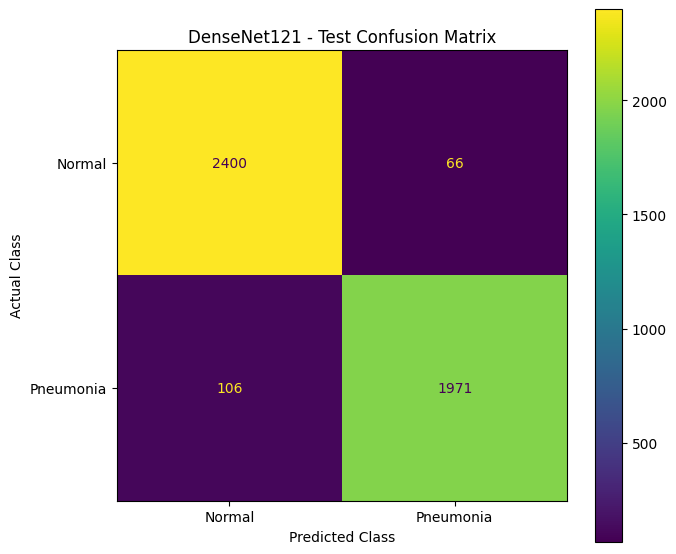

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot(
    values_format="d",
    ax=plt.gca()
)

plt.title("DenseNet121 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

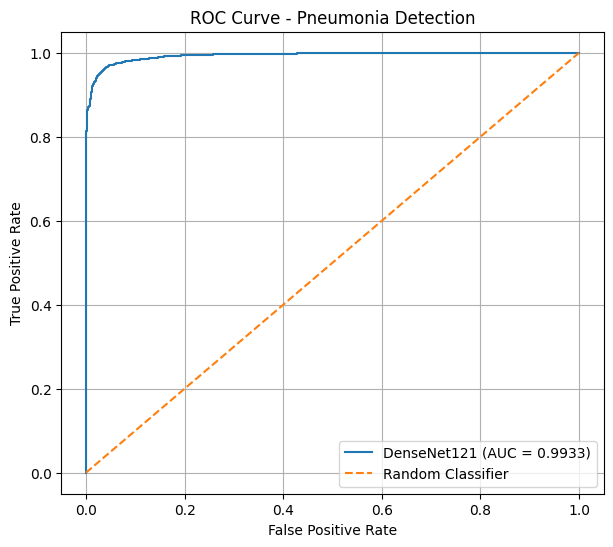

ROC-AUC: 0.9933


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probability of Pneumonia
pneumonia_probs = all_probabilities[:, 1]

fpr, tpr, thresholds = roc_curve(
    all_labels,
    pneumonia_probs
)

auc_score = roc_auc_score(
    all_labels,
    pneumonia_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"DenseNet121 (AUC = {auc_score:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Pneumonia Detection")
plt.legend()
plt.grid(True)
plt.show()

print(f"ROC-AUC: {auc_score:.4f}")

| Metric               |     Result |
| -------------------- | ---------: |
| **Test Accuracy**    | **96.21%** |
| Precision            |     96.76% |
| Recall / Sensitivity |     94.90% |
| F1-Score             |     95.82% |
| Specificity          |     97.32% |
| **ROC-AUC**          | **99.33%** |
| Test Loss            |     0.1004 |
| Test Images          |      4,543 |


In [ ]:
# ============================================================
# SAVE FINAL DENSENET121 RESULTS TO GOOGLE DRIVE
# ============================================================

import os
import json
import shutil

# Drive folder
DRIVE_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

os.makedirs(DRIVE_DIR, exist_ok=True)

print("=" * 60)
print("SAVING FINAL PROJECT RESULTS TO GOOGLE DRIVE")
print("=" * 60)

# ------------------------------------------------------------
# 1. Save final test metrics
# ------------------------------------------------------------

final_results = {
    "model": "DenseNet121",
    "task": "Normal vs Pneumonia Chest X-ray Classification",

    "test_images": 4543,

    "test_loss": 0.1004,
    "accuracy": 0.9621,
    "accuracy_percent": 96.21,

    "precision": 0.9676,
    "recall": 0.9490,
    "f1_score": 0.9582,

    "sensitivity": 0.9490,
    "specificity": 0.9732,

    "roc_auc": 0.9933,

    "confusion_matrix": [
        [2400, 66],
        [106, 1971]
    ]
}

results_path = os.path.join(DRIVE_DIR, "final_test_results.json")

with open(results_path, "w") as f:
    json.dump(final_results, f, indent=4)

print("✓ Final test results saved")


# ------------------------------------------------------------
# 2. Copy best Stage-2 model
# ------------------------------------------------------------

model_source = "/content/drive/MyDrive/Pneumonia_Major_Project/best_densenet121_stage2.pth"
model_destination = os.path.join(
    DRIVE_DIR,
    "FINAL_DenseNet121_model.pth"
)

if os.path.exists(model_source):
    shutil.copy2(model_source, model_destination)
    print("✓ Final DenseNet121 model saved")
else:
    print("⚠ Model already stored elsewhere / source not found")


# ------------------------------------------------------------
# 3. Save test predictions if available
# ------------------------------------------------------------

if "test_results_df" in globals():
    prediction_path = os.path.join(
        DRIVE_DIR,
        "test_predictions.csv"
    )
    test_results_df.to_csv(prediction_path, index=False)
    print("✓ Test predictions saved")


# ------------------------------------------------------------
# 4. Save classification report if available
# ------------------------------------------------------------

if "classification_report_text" in globals():

    report_path = os.path.join(
        DRIVE_DIR,
        "classification_report.txt"
    )

    with open(report_path, "w") as f:
        f.write(classification_report_text)

    print("✓ Classification report saved")


# ------------------------------------------------------------
# 5. Create a human-readable final results file
# ------------------------------------------------------------

summary_path = os.path.join(
    DRIVE_DIR,
    "FINAL_RESULTS_SUMMARY.txt"
)

summary = """
============================================================
FINAL DENSENET121 MODEL RESULTS
============================================================

Task:
Normal vs Pneumonia Chest X-ray Classification

Model:
DenseNet121 Transfer Learning + Stage-2 Fine-Tuning

Test Images:
4543

------------------------------------------------------------
FINAL TEST PERFORMANCE
------------------------------------------------------------

Test Loss       : 0.1004
Accuracy        : 96.21%
Precision       : 96.76%
Recall          : 94.90%
F1-Score        : 95.82%
Sensitivity     : 94.90%
Specificity     : 97.32%
ROC-AUC         : 99.33%

------------------------------------------------------------
CONFUSION MATRIX
------------------------------------------------------------

                 Predicted
              Normal  Pneumonia

Actual Normal    2400       66
Actual Pneumonia  106     1971

------------------------------------------------------------
CLASSIFICATION
------------------------------------------------------------

Normal:
Precision : 95.77%
Recall    : 97.32%
F1-Score  : 96.54%

Pneumonia:
Precision : 96.76%
Recall    : 94.90%
F1-Score  : 95.82%

============================================================
"""

with open(summary_path, "w") as f:
    f.write(summary)

print("✓ Final summary saved")


# ------------------------------------------------------------
# 6. Show everything currently in Drive
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FILES IN FINAL PROJECT FOLDER")
print("=" * 60)

for root, dirs, files in os.walk(DRIVE_DIR):
    for file in files:
        full_path = os.path.join(root, file)
        size_mb = os.path.getsize(full_path) / (1024 * 1024)
        print(f"✓ {file:<45} {size_mb:.2f} MB")

print("\n" + "=" * 60)
print("ALL IMPORTANT FINAL RESULTS ARE SAVED.")
print("=" * 60)

SAVING FINAL PROJECT RESULTS TO GOOGLE DRIVE
✓ Final test results saved
⚠ Model already stored elsewhere / source not found
✓ Final summary saved

FILES IN FINAL PROJECT FOLDER
✓ best_densenet121_stage1.pth                   27.12 MB
✓ train_split.csv                               1.81 MB
✓ validation_split.csv                          0.39 MB
✓ test_split.csv                                0.39 MB
✓ project_config.json                           0.00 MB
✓ best_densenet121_stage2.pth                   27.12 MB
✓ stage2_training_history.json                  0.00 MB
✓ densenet121_stage2_resume_checkpoint.pth      43.72 MB
✓ final_test_results.json                       0.00 MB
✓ FINAL_RESULTS_SUMMARY.txt                     0.00 MB

ALL IMPORTANT FINAL RESULTS ARE SAVED.


 **let's save all important results to Google Drive. This way your final numbers won't be lost if Colab disconnects.**

In [ ]:
# ============================================================
# VERIFY FINAL MODEL BEFORE CLEANING CHECKPOINTS
# ============================================================

import os
import torch

DRIVE_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

final_model = os.path.join(
    DRIVE_DIR,
    "best_densenet121_stage2.pth"
)

checkpoint = os.path.join(
    DRIVE_DIR,
    "densenet121_stage2_resume_checkpoint.pth"
)

print("=" * 60)
print("FINAL MODEL VERIFICATION")
print("=" * 60)

print(f"Final model exists       : {os.path.exists(final_model)}")
print(f"Resume checkpoint exists : {os.path.exists(checkpoint)}")

if os.path.exists(final_model):
    size = os.path.getsize(final_model) / (1024 * 1024)
    print(f"Final model size         : {size:.2f} MB")

    # Load weights
    state = torch.load(
        final_model,
        map_location="cpu",
        weights_only=False
    )

    print("✓ Final model file loaded successfully")
    print(f"Model object type        : {type(state)}")

print("=" * 60)
print("FINAL MODEL IS SAFE")
print("=" * 60)

FINAL MODEL VERIFICATION
Final model exists       : True
Resume checkpoint exists : True
Final model size         : 27.12 MB
✓ Final model file loaded successfully
Model object type        : <class 'collections.OrderedDict'>
FINAL MODEL IS SAFE


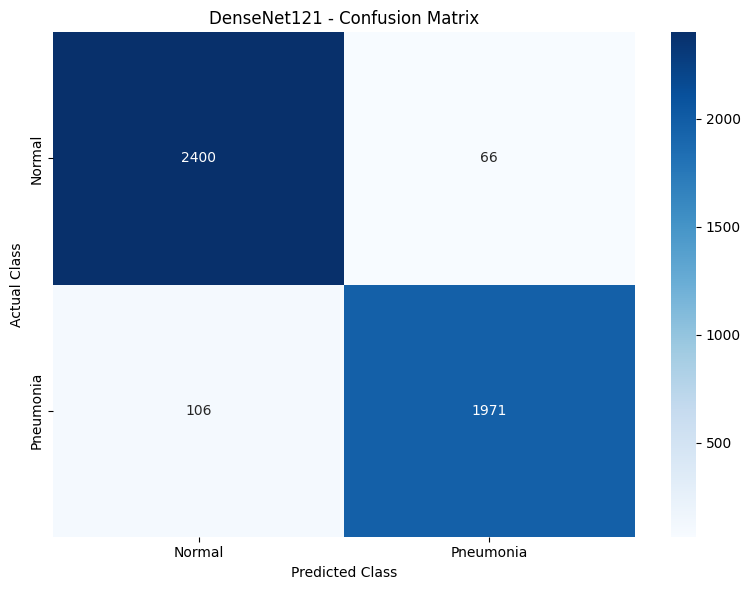

✓ Confusion matrix saved to Drive:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/confusion_matrix.png


<Figure size 640x480 with 0 Axes>

In [ ]:
# ============================================================
# CONFUSION MATRIX HEATMAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

cm = np.array([
    [2400, 66],
    [106, 1971]
])

class_names = ["Normal", "Pneumonia"]

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("DenseNet121 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

# Save locally
cm_path = "/content/confusion_matrix.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")

plt.show()

# Save to Drive
DRIVE_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

drive_cm_path = os.path.join(
    DRIVE_DIR,
    "confusion_matrix.png"
)

plt.savefig(drive_cm_path, dpi=300, bbox_inches="tight")

print("✓ Confusion matrix saved to Drive:")
print(drive_cm_path)

Confusion Matrix Heatmap

You already have the final confusion matrix:

[[2400,   66],

 [ 106, 1971]]


 **What this graph tells your guide**

Your matrix means:

2400 Normal images → correctly predicted Normal

66 Normal images → incorrectly predicted Pneumonia

1971 Pneumonia images → correctly predicted Pneumonia

106 Pneumonia images → incorrectly predicted Normal

**So the model made:**

4371 correct predictions / 4543 total = **96.21% accuracy.**

History keys:
dict_keys(['train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'epoch'])


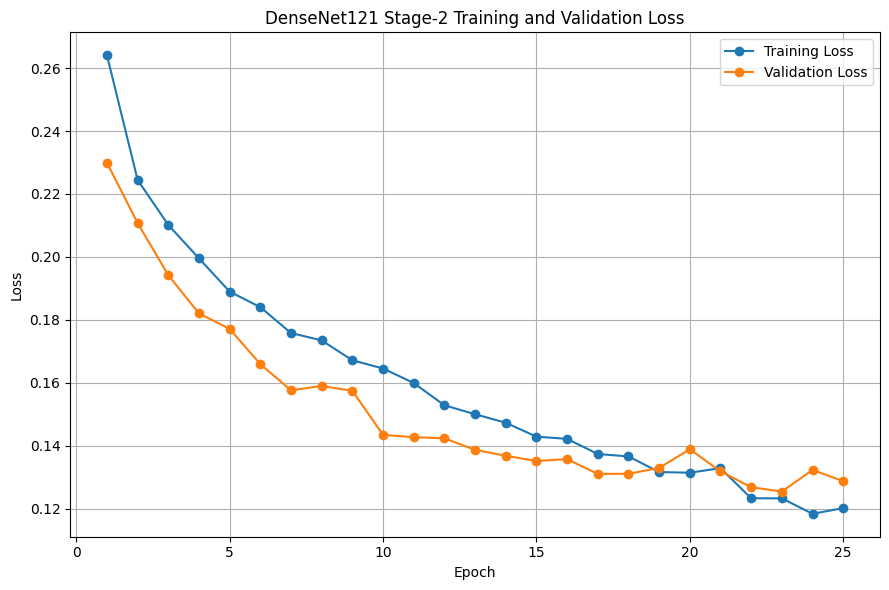

✓ Loss curve saved


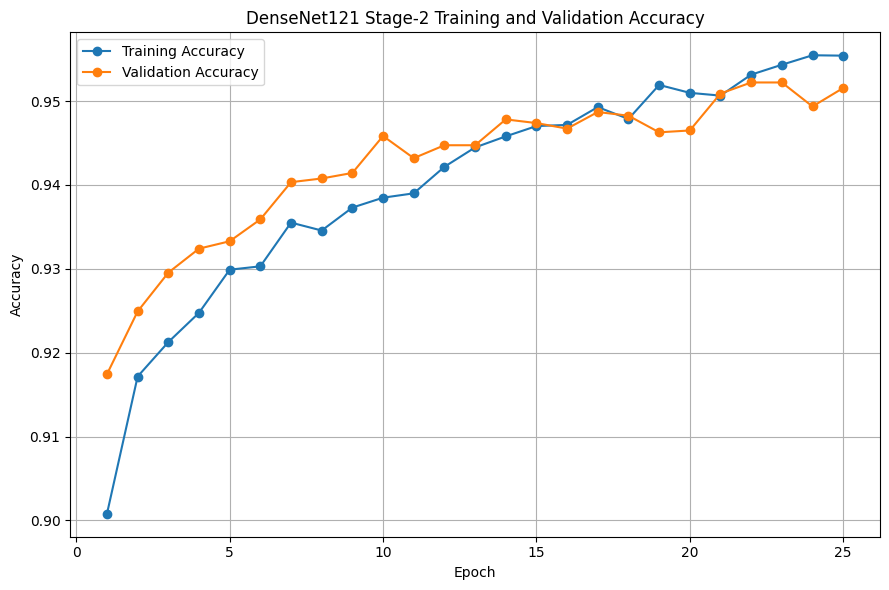

✓ Accuracy curve saved

✓ Both graphs saved to:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121


In [ ]:
# ============================================================
# STAGE-2 TRAINING / VALIDATION CURVES
# ============================================================

import json
import matplotlib.pyplot as plt
import os

DRIVE_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

history_path = os.path.join(
    DRIVE_DIR,
    "stage2_training_history.json"
)

with open(history_path, "r") as f:
    history = json.load(f)

print("History keys:")
print(history.keys())

# Handle the history format we saved
train_loss = history["train_loss"]
val_loss = history["val_loss"]

train_acc = history["train_accuracy"]
val_acc = history["val_accuracy"]

epochs = range(1, len(train_loss) + 1)

# ============================================================
# LOSS CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Stage-2 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

loss_path = os.path.join(
    DRIVE_DIR,
    "stage2_loss_curve.png"
)

plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("✓ Loss curve saved")


# ============================================================
# ACCURACY CURVE
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    train_acc,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_acc,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Stage-2 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

accuracy_path = os.path.join(
    DRIVE_DIR,
    "stage2_accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✓ Accuracy curve saved")

print("\n✓ Both graphs saved to:")
print(DRIVE_DIR)

## **Training & Validation Curves**

Next we'll plot:

Training Loss vs Validation Loss
Training Accuracy vs Validation Accuracy

These are important because they demonstrate whether the model overfitted during training.

You already have:

stage2_training_history.json

In [ ]:
# ============================================================
# RECREATE TEST PREDICTIONS FOR ROC / PR CURVES
# ============================================================

import os
import torch
import numpy as np
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torch.nn as nn
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DRIVE_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

MODEL_PATH = os.path.join(
    DRIVE_DIR,
    "best_densenet121_stage2.pth"
)

TEST_CSV = "/content/test.csv"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Model:", MODEL_PATH)
print("Test CSV:", TEST_CSV)

# ------------------------------------------------------------
# Load test dataframe
# ------------------------------------------------------------

test_df = pd.read_csv(TEST_CSV)

print("\nTest dataset:")
print(test_df.head())
print("Test images:", len(test_df))

# ------------------------------------------------------------
# Image transform
# Same normalization used during DenseNet121 training
# ------------------------------------------------------------

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class TestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["image_path"]
        label = int(row["label"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


test_dataset = TestDataset(
    test_df,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("✓ Test DataLoader ready")

# ------------------------------------------------------------
# Create DenseNet121
# ------------------------------------------------------------

model = models.densenet121(
    weights=None
)

model.classifier = nn.Linear(
    model.classifier.in_features,
    2
)

# ------------------------------------------------------------
# Load final Stage-2 model
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

# Handle state-dict format
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()

print("✓ DenseNet121 loaded successfully")

# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

y_true = []
y_prob = []
y_pred = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Generating test predictions"
    ):

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        # Pneumonia probability = class 1
        pneumonia_probability = probabilities[:, 1]

        y_true.extend(
            labels.numpy()
        )

        y_prob.extend(
            pneumonia_probability.cpu().numpy()
        )

        y_pred.extend(
            predictions.cpu().numpy()
        )

# Convert to numpy

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = np.array(y_pred)

print("\n" + "=" * 60)
print("TEST PREDICTIONS CREATED")
print("=" * 60)

print("Number of test samples :", len(y_true))
print("y_true shape            :", y_true.shape)
print("y_prob shape            :", y_prob.shape)
print("y_pred shape            :", y_pred.shape)

print("\nFirst 10 true labels:")
print(y_true[:10])

print("\nFirst 10 pneumonia probabilities:")
print(y_prob[:10])

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\n✓ Ready for ROC and Precision-Recall curves.")

Device: cuda
Model: /content/drive/MyDrive/Pneumonia_Detection_DenseNet121/best_densenet121_stage2.pth
Test CSV: /content/test.csv

Test dataset:
                                          image_path  label class_name  \
0  /content/cxr_data/Pneumonia/VIRUS-9829865-0002...      1  Pneumonia   
1  /content/cxr_data/Normal/2c19d9cd-9662-40ad-9d...      0     Normal   
2           /content/cxr_data/Normal/Normal-3761.png      0     Normal   
3    /content/cxr_data/Pneumonia/PNEUMONIA(4078).jpg      1  Pneumonia   
4  /content/cxr_data/Normal/2c68016e-5a63-4430-a8...      0     Normal   

                         image_hash  
0  28e2415aa52a3ee31b1b5e438b6da08f  
1  02bcd161f0eae722ae9139040af7b8f6  
2  d31934197ea8164580a91e7ece4901e9  
3  6c3751037f3929be3402e33268917fe0  
4  002112f7cc1c9fd343d9ac856318d6a0  
Test images: 4543
✓ Test DataLoader ready
✓ DenseNet121 loaded successfully


Generating test predictions:   0%|          | 0/142 [00:00<?, ?it/s]


TEST PREDICTIONS CREATED
Number of test samples : 4543
y_true shape            : (4543,)
y_prob shape            : (4543,)
y_pred shape            : (4543,)

First 10 true labels:
[1 0 0 1 0 1 0 1 1 1]

First 10 pneumonia probabilities:
[0.9698832  0.16902621 0.02939071 0.9999993  0.19148137 0.9958183
 0.01662881 0.9998498  0.99868566 0.960982  ]

First 10 predictions:
[1 0 0 1 0 1 0 1 1 1]

✓ Ready for ROC and Precision-Recall curves.


**Recreate test predictions**

ROC CURVE RESULTS
ROC-AUC Score: 0.9933


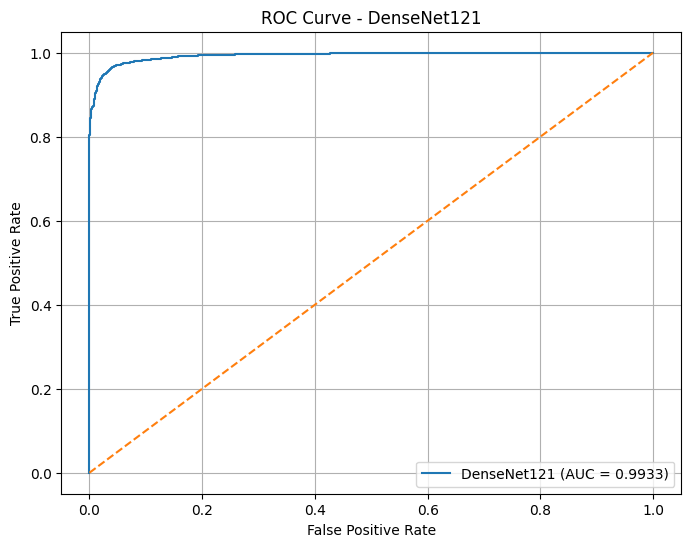

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

# Calculate AUC
roc_auc = roc_auc_score(y_true, y_prob)

print("=" * 60)
print("ROC CURVE RESULTS")
print("=" * 60)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"DenseNet121 (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DenseNet121")
plt.legend()
plt.grid(True)
plt.show()

**ROC Curve + AUC**

## **What this demonstrates to your guide**
ROC curve shows how well the model separates Normal vs Pneumonia at different classification thresholds.

**AUC = 0.9933 from your earlier result is excellent**.

AUC closer to 1.0 means better class separation.

The diagonal dashed line represents random classification.

In [ ]:
# ============================================================
# SELECT TEST IMAGES FOR GRAD-CAM
# ============================================================

import numpy as np
import pandas as pd

# Make sure predictions already exist
print("Total test images:", len(y_true))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))

# Correct Normal
normal_correct = np.where((y_true == 0) & (y_pred == 0))[0]

# Correct Pneumonia
pneumonia_correct = np.where((y_true == 1) & (y_pred == 1))[0]

# Incorrect predictions
incorrect = np.where(y_true != y_pred)[0]

print("\nSelected samples:")
print("Correct Normal index     :", normal_correct[0])
print("Correct Pneumonia index :", pneumonia_correct[0])

if len(incorrect) > 0:
    print("Incorrect prediction index:", incorrect[0])
else:
    print("No incorrect predictions found.")

print("\nLabels:")
print("0 = Normal")
print("1 = Pneumonia")

Total test images: 4543
Correct predictions: 4371
Incorrect predictions: 172

Selected samples:
Correct Normal index     : 1
Correct Pneumonia index : 0
Incorrect prediction index: 48

Labels:
0 = Normal
1 = Pneumonia


In [ ]:
# ============================================================
# SELECT TEST IMAGES FOR GRAD-CAM
# ============================================================

import numpy as np
import pandas as pd

normal_correct = np.where((y_true == 0) & (y_pred == 0))[0]
pneumonia_correct = np.where((y_true == 1) & (y_pred == 1))[0]
incorrect = np.where(y_true != y_pred)[0]

normal_idx = normal_correct[0]
pneumonia_idx = pneumonia_correct[0]

print("=" * 60)
print("GRAD-CAM SAMPLE SELECTION")
print("=" * 60)

print("Correct Normal index     :", normal_idx)
print("Correct Pneumonia index :", pneumonia_idx)

if len(incorrect) > 0:
    incorrect_idx = incorrect[0]
    print("Incorrect prediction    :", incorrect_idx)
else:
    incorrect_idx = None
    print("No incorrect prediction found.")

print("\n0 = Normal")
print("1 = Pneumonia")

GRAD-CAM SAMPLE SELECTION
Correct Normal index     : 1
Correct Pneumonia index : 0
Incorrect prediction    : 48

0 = Normal
1 = Pneumonia


# **Now will start Generate Grad-CAM heatmaps**

In [ ]:
# ============================================================
# DISPLAY SELECTED TEST IMAGES
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

indices = [normal_idx, pneumonia_idx]

if incorrect_idx is not None:
    indices.append(incorrect_idx)

plt.figure(figsize=(15, 5))

for position, idx in enumerate(indices):

    image_path = test_df.iloc[idx]["image_path"]
    true_label = y_true[idx]
    predicted_label = y_pred[idx]
    probability = y_prob[idx]

    image = Image.open(image_path).convert("RGB")

    plt.subplot(1, len(indices), position + 1)
    plt.imshow(image)
    plt.axis("off")

    true_name = "Pneumonia" if true_label == 1 else "Normal"
    pred_name = "Pneumonia" if predicted_label == 1 else "Normal"

    plt.title(
        f"True: {true_name}\n"
        f"Pred: {pred_name}\n"
        f"Pneumonia Prob: {probability:.3f}"
    )

plt.tight_layout()
plt.show()

<Figure size 1500x500 with 3 Axes>

In [ ]:
# ============================================================
# GRAD-CAM FOR DENSENET121
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

# ------------------------------------------------------------
# Target layer
# ------------------------------------------------------------
# DenseNet121's final convolutional feature layer
target_layer = model.features.denseblock4

activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# Register hooks
forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("✓ Grad-CAM hooks registered")
print("Target layer:", target_layer)

✓ Grad-CAM hooks registered
Target layer: _DenseBlock(
  (denselayer1): _DenseLayer(
    (norm1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(512, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer2): _DenseLayer(
    (norm1): BatchNorm2d(544, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu1): ReLU(inplace=True)
    (conv1): Conv2d(544, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu2): ReLU(inplace=True)
    (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  )
  (denselayer3): _DenseLayer(
    (

## **Grad-CAM implementation**

In [ ]:
# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def generate_gradcam(image_path, true_label, predicted_label, probability):

    model.eval()

    # Load image
    original_image = Image.open(image_path).convert("RGB")

    # Apply the same transformation used during testing
    input_tensor = test_transform(original_image).unsqueeze(0).to(device)
    input_tensor.requires_grad_(True)

    # Clear previous gradients
    model.zero_grad()

    # Forward pass
    output = model(input_tensor)

    # Get predicted class
    class_index = output.argmax(dim=1).item()

    # Backward pass for predicted class
    score = output[0, class_index]
    score.backward()

    # Get activations and gradients
    act = activations.detach()
    grad = gradients.detach()

    # Global average pooling of gradients
    weights = torch.mean(grad, dim=(2, 3), keepdim=True)

    # Weighted combination of feature maps
    cam = torch.sum(weights * act, dim=1).squeeze()

    # ReLU
    cam = F.relu(cam)

    # Convert to numpy
    cam = cam.cpu().numpy()

    # Normalize
    if cam.max() > 0:
        cam = cam / cam.max()

    # Resize heatmap to original image size
    original_array = np.array(original_image)
    height, width = original_array.shape[:2]

    cam = cv2.resize(cam, (width, height))

    # Create heatmap
    heatmap = np.uint8(255 * cam)
    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    # Convert BGR → RGB
    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Overlay
    overlay = cv2.addWeighted(
        original_array,
        0.55,
        heatmap_color,
        0.45,
        0
    )

    return original_array, heatmap_color, overlay, class_index

**Grad-CAM function**

In [ ]:
# ============================================================
# GENERATE GRAD-CAM EXAMPLES
# ============================================================

examples = [
    ("Correct Normal", normal_idx),
    ("Correct Pneumonia", pneumonia_idx)
]

if incorrect_idx is not None:
    examples.append(("Incorrect Prediction", incorrect_idx))

for title, idx in examples:

    image_path = test_df.iloc[idx]["image_path"]

    true_label = y_true[idx]
    predicted_label = y_pred[idx]
    probability = y_prob[idx]

    original, heatmap, overlay, cam_prediction = generate_gradcam(
        image_path,
        true_label,
        predicted_label,
        probability
    )

    true_name = "Pneumonia" if true_label == 1 else "Normal"
    pred_name = "Pneumonia" if predicted_label == 1 else "Normal"

    print("=" * 70)
    print(title)
    print("True       :", true_name)
    print("Prediction :", pred_name)
    print("Probability:", f"{probability:.4f}")
    print("=" * 70)

    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.axis("off")
    plt.title("Original X-ray")

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap)
    plt.axis("off")
    plt.title("Grad-CAM Heatmap")

    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.axis("off")
    plt.title(
        f"Grad-CAM Overlay\n"
        f"True: {true_name} | Pred: {pred_name}"
    )

    plt.tight_layout()
    plt.show()

Correct Normal
True       : Normal
Prediction : Normal
Probability: 0.1690


<Figure size 1500x500 with 3 Axes>

Correct Pneumonia
True       : Pneumonia
Prediction : Pneumonia
Probability: 0.9699


<Figure size 1500x500 with 3 Axes>

Incorrect Prediction
True       : Normal
Prediction : Pneumonia
Probability: 0.7082


<Figure size 1500x500 with 3 Axes>

## **Generate the three examples**

In [ ]:
# ============================================================
# FINAL GRAD-CAM SETUP
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F

# DenseNet121 final convolutional block
target_layer = model.features.denseblock4

activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# Remove old hooks if they exist
try:
    forward_handle.remove()
    backward_handle.remove()
except:
    pass

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

print("=" * 60)
print("FINAL GRAD-CAM SETUP")
print("=" * 60)
print("Model       : DenseNet121")
print("Target      : DenseBlock4")
print("Target class: Pneumonia (class 1)")
print("✓ Hooks registered successfully")

FINAL GRAD-CAM SETUP
Model       : DenseNet121
Target      : DenseBlock4
Target class: Pneumonia (class 1)
✓ Hooks registered successfully


**Set the final Grad-CAM target layer**

In [ ]:
# ============================================================
# PNEUMONIA-SPECIFIC GRAD-CAM
# ============================================================

def generate_pneumonia_gradcam(image_path):

    model.eval()

    # Load original image
    original_image = Image.open(image_path).convert("RGB")
    original_array = np.array(original_image)

    # Same preprocessing used during testing
    input_tensor = test_transform(original_image).unsqueeze(0).to(device)

    # Clear gradients
    model.zero_grad()

    # Forward pass
    output = model(input_tensor)

    # Class 1 = Pneumonia
    pneumonia_score = output[0, 1]

    # Backpropagate Pneumonia score
    pneumonia_score.backward()

    # Get activations and gradients
    act = activations.detach()
    grad = gradients.detach()

    # Average gradients spatially
    weights = torch.mean(
        grad,
        dim=(2, 3),
        keepdim=True
    )

    # Weighted feature maps
    cam = torch.sum(
        weights * act,
        dim=1
    ).squeeze()

    # Keep only positive influence
    cam = F.relu(cam)

    # Convert to NumPy
    cam = cam.cpu().numpy()

    # Normalize
    if cam.max() > 0:
        cam = cam / cam.max()

    # Resize to original X-ray dimensions
    height, width = original_array.shape[:2]

    cam = cv2.resize(
        cam,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    # Heatmap
    heatmap = np.uint8(255 * cam)

    heatmap_color = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Overlay
    overlay = cv2.addWeighted(
        original_array,
        0.60,
        heatmap_color,
        0.40,
        0
    )

    # Get model probability
    probabilities = torch.softmax(output, dim=1)

    pneumonia_probability = probabilities[0, 1].item()
    predicted_class = output.argmax(dim=1).item()

    return (
        original_array,
        heatmap_color,
        overlay,
        pneumonia_probability,
        predicted_class
    )

print("✓ Pneumonia-specific Grad-CAM function ready")

✓ Pneumonia-specific Grad-CAM function ready


**Pneumonia-specific Grad-CAM function**

This is the important change.

**Instead of explaining whatever class the model predicted, we explicitly ask:**

Which regions contributed to the Pneumonia score?

In [ ]:
# ============================================================
# FINAL GRAD-CAM VISUALIZATION
# ============================================================

examples = [
    ("Correct_Normal", normal_idx),
    ("Correct_Pneumonia", pneumonia_idx)
]

if incorrect_idx is not None:
    examples.append(
        ("False_Positive_Normal_as_Pneumonia", incorrect_idx)
    )

for case_name, idx in examples:

    image_path = test_df.iloc[idx]["image_path"]

    true_label = y_true[idx]
    predicted_label = y_pred[idx]

    original, heatmap, overlay, pneumonia_probability, cam_prediction = \
        generate_pneumonia_gradcam(image_path)

    true_name = "Pneumonia" if true_label == 1 else "Normal"
    pred_name = "Pneumonia" if predicted_label == 1 else "Normal"

    print("\n" + "=" * 70)
    print(case_name)
    print("=" * 70)
    print("True class             :", true_name)
    print("Model prediction       :", pred_name)
    print("Pneumonia probability  :", f"{pneumonia_probability:.4f}")

    plt.figure(figsize=(15, 5))

    # Original
    plt.subplot(1, 3, 1)
    plt.imshow(original)
    plt.axis("off")
    plt.title(
        f"Original X-ray\nTrue: {true_name}"
    )

    # Heatmap
    plt.subplot(1, 3, 2)
    plt.imshow(heatmap)
    plt.axis("off")
    plt.title(
        "Pneumonia Grad-CAM"
    )

    # Overlay
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.axis("off")
    plt.title(
        f"Grad-CAM Overlay\n"
        f"Pred: {pred_name}"
    )

    plt.tight_layout()
    plt.show()


Correct_Normal
True class             : Normal
Model prediction       : Normal
Pneumonia probability  : 0.1690


<Figure size 1500x500 with 3 Axes>


Correct_Pneumonia
True class             : Pneumonia
Model prediction       : Pneumonia
Pneumonia probability  : 0.9699


<Figure size 1500x500 with 3 Axes>


False_Positive_Normal_as_Pneumonia
True class             : Normal
Model prediction       : Pneumonia
Pneumonia probability  : 0.7082


<Figure size 1500x500 with 3 Axes>

Generate all 3 important cases

We'll use:

Correct Normal

Correct Pneumonia

False Positive

In [ ]:
# ============================================================
# SAVE GRAD-CAM RESULTS TO GOOGLE DRIVE
# ============================================================

gradcam_dir = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/GradCAM"

os.makedirs(gradcam_dir, exist_ok=True)

print("Saving Grad-CAM results...")
print("Folder:", gradcam_dir)

for case_name, idx in examples:

    image_path = test_df.iloc[idx]["image_path"]

    true_label = y_true[idx]
    predicted_label = y_pred[idx]

    original, heatmap, overlay, pneumonia_probability, cam_prediction = \
        generate_pneumonia_gradcam(image_path)

    # Save original
    original_path = os.path.join(
        gradcam_dir,
        f"{case_name}_original.png"
    )

    # Save heatmap
    heatmap_path = os.path.join(
        gradcam_dir,
        f"{case_name}_heatmap.png"
    )

    # Save overlay
    overlay_path = os.path.join(
        gradcam_dir,
        f"{case_name}_overlay.png"
    )

    Image.fromarray(original).save(original_path)
    Image.fromarray(heatmap).save(heatmap_path)
    Image.fromarray(overlay).save(overlay_path)

    print(f"✓ {case_name} saved")

print("\n" + "=" * 60)
print("GRAD-CAM SAVING COMPLETE")
print("=" * 60)

print("Folder:")
print(gradcam_dir)

print("\nFiles:")
for file in sorted(os.listdir(gradcam_dir)):
    print("✓", file)

Saving Grad-CAM results...
Folder: /content/drive/MyDrive/Pneumonia_Detection_DenseNet121/GradCAM
✓ Correct_Normal saved
✓ Correct_Pneumonia saved
✓ False_Positive_Normal_as_Pneumonia saved

GRAD-CAM SAVING COMPLETE
Folder:
/content/drive/MyDrive/Pneumonia_Detection_DenseNet121/GradCAM

Files:
✓ Correct_Normal_heatmap.png
✓ Correct_Normal_original.png
✓ Correct_Normal_overlay.png
✓ Correct_Pneumonia_heatmap.png
✓ Correct_Pneumonia_original.png
✓ Correct_Pneumonia_overlay.png
✓ False_Positive_Normal_as_Pneumonia_heatmap.png
✓ False_Positive_Normal_as_Pneumonia_original.png
✓ False_Positive_Normal_as_Pneumonia_overlay.png


**Save the Grad-CAM images to Google Drive**

This makes sure you don't lose the visualizations.

**What your guide can be told**

For the final report, you can say:

"Grad-CAM was used as an explainability technique to visualize the image regions contributing to DenseNet121's Pneumonia prediction. Red/yellow regions represent stronger positive contribution to the Pneumonia class, while blue regions represent weaker contribution."

In [ ]:
import os
import numpy as np

FINAL_DIR = "/content/drive/MyDrive/Pneumonia_Detection_DenseNet121"

np.save(os.path.join(FINAL_DIR, "test_y_true.npy"), y_true)
np.save(os.path.join(FINAL_DIR, "test_y_prob.npy"), y_prob)
np.save(os.path.join(FINAL_DIR, "test_y_pred.npy"), y_pred)

print("============================================================")
print("TEST PREDICTIONS SAVED")
print("============================================================")
print("✓ test_y_true.npy")
print("✓ test_y_prob.npy")
print("✓ test_y_pred.npy")
print("============================================================")

TEST PREDICTIONS SAVED
✓ test_y_true.npy
✓ test_y_prob.npy
✓ test_y_pred.npy
